# Growth, Structural Shifts and Forecasting of UPI Transaction Volumes in India (2016–2026)

**Programme:** M.Sc. Economics – Data Analytics | **Course:** Python for Data Science
**Data source:** National Payments Corporation of India (NPCI), UPI Product Statistics (monthly)

**Research question:** What are the long-term growth and structural trends in UPI transaction volume and value in India, and how accurately can near-term monthly transactions be forecast using historical patterns?


## 0. Setup

In [ ]:
import warnings, itertools, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan, breaks_cusumolsresid
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (9, 5)

# Google Drive folder that holds the 11 NPCI files (upi_2016_17.xlsx ... upi_2026_27.xlsx)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive/upi_project/'
except ImportError:
    DATA_DIR = './upi_project/'          # running outside Colab
print("Data folder:", DATA_DIR)

Mounted at /content/drive
Data folder: /content/drive/MyDrive/upi_project/


## 1. Data acquisition and inspection

NPCI's Product Statistics page exports one financial year at a time, so 11 files (FY2016-17 to FY2026-27) were downloaded and stacked.

In [ ]:
files = sorted(glob.glob(DATA_DIR + 'upi_*.xlsx'))
print(len(files), "files found")
for f in files:
    print(" ", f.split('/')[-1])

df_raw = pd.concat([pd.read_excel(f) for f in files], ignore_index=True)
df_raw.to_csv(DATA_DIR + '02_Raw_Data.csv', index=False)     # untouched raw copy
print("\nRaw shape:", df_raw.shape)

11 files found
  upi_2016_17.xlsx
  upi_2017_18.xlsx
  upi_2018_19.xlsx
  upi_2019_20.xlsx
  upi_2020_21.xlsx
  upi_2021_22.xlsx
  upi_2022_23.xlsx
  upi_2023_24.xlsx
  upi_2024_25.xlsx
  upi_2025_26.xlsx
  upi_2026_27.xlsx

Raw shape: (123, 4)


In [ ]:
display(df_raw.head())
print(df_raw.columns.tolist())
df_raw.info()
print("\nMissing values:\n", df_raw.isnull().sum())
print("\nDuplicate rows:", df_raw.duplicated().sum())

,Month,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.)
0,March-2017,44,6.37,2425.14
1,February-2017,44,4.38,1937.71
2,January-2017,36,4.46,1696.22
3,December-2016,35,1.99,707.93
4,November-2016,30,0.29,100.46


['Month', 'No. of Banks live on UPI', 'Volume (In Mn.)', 'Value (In Cr.)']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123 entries, 0 to 122
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Month                     123 non-null    object
 1   No. of Banks live on UPI  123 non-null    int64 
 2   Volume (In Mn.)           123 non-null    object
 3   Value (In Cr.)            123 non-null    object
dtypes: int64(1), object(3)
memory usage: 4.0+ KB

Missing values:
 Month                       0
No. of Banks live on UPI    0
Volume (In Mn.)             0
Value (In Cr.)              0
dtype: int64

Duplicate rows: 0


### Data dictionary

| Variable | Meaning | Data type | Unit | Role |
|---|---|---|---|---|
| Month | Month of observation | Text → datetime | Month-Year | Time index |
| banks_live | Banks live on the UPI network that month | Integer | Count | Descriptive variable |
| volume_mn | Number of UPI transactions | Text → float | Millions | **Target** |
| value_cr | Value of UPI transactions | Text → float | ₹ crore | Secondary outcome / descriptive |

**Note from NPCI:** transactions with debit and credit to the same account are excluded from August 2018 onwards, so figures before and after that month are not perfectly comparable.

**Missing values.** `isnull().sum()` returned zero in all four columns, as expected for an official monthly release. No imputation was required.

## 2. Data cleaning

In [ ]:
df = df_raw.copy()

# 1) rename unclear / space-containing columns
df = df.rename(columns={
    "No. of Banks live on UPI": "banks_live",
    "Volume (In Mn.)": "volume_mn",
    "Value (In Cr.)": "value_cr",
})

# 2) numeric columns arrive as text with thousands separators ("22,716.07")
for c in ["volume_mn", "value_cr"]:
    df[c] = df[c].astype(str).str.replace(",", "", regex=False).astype(float)

# 3) month text -> datetime, then sort chronologically
df["Month"] = pd.to_datetime(df["Month"], format="%B-%Y")
df = df.sort_values("Month").reset_index(drop=True)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123 entries, 0 to 122
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Month       123 non-null    datetime64[ns]
 1   banks_live  123 non-null    int64         
 2   volume_mn   123 non-null    float64       
 3   value_cr    123 non-null    float64       
dtypes: datetime64[ns](1), float64(2), int64(1)
memory usage: 4.0 KB


In [ ]:
# Duplicate and completeness checks on the time index
print("Duplicate months:", df["Month"].duplicated().sum())

full_range = pd.date_range(df["Month"].min(), df["Month"].max(), freq="MS")
print("Missing calendar months:", len(full_range.difference(df["Month"])))
print("Period:", df["Month"].min().strftime("%b-%Y"), "to", df["Month"].max().strftime("%b-%Y"))

# Invalid / suspicious values
print("\nMonths with zero or negative volume or value:")
display(df[(df["volume_mn"] <= 0) | (df["value_cr"] <= 0)])

Duplicate months: 0
Missing calendar months: 0
Period: Apr-2016 to Jun-2026

Months with zero or negative volume or value:


,Month,banks_live,volume_mn,value_cr
0,2016-04-01,21,0.0,0.0
1,2016-05-01,21,0.0,0.0
2,2016-06-01,21,0.0,0.0


In [ ]:
# Derived variables
df["year"] = df["Month"].dt.year
df["month_num"] = df["Month"].dt.month

# Month-on-month % change. April 2016 volume is 0, so the change into May 2016 is
# undefined (inf). It is set to NaN instead of being kept as inf.
df["volume_growth_pct"] = df["volume_mn"].pct_change().replace([np.inf, -np.inf], np.nan) * 100

print("Infinite growth values left:", np.isinf(df["volume_growth_pct"]).sum())
print("Raw shape:", df_raw.shape, "-> Cleaned shape:", df.shape)

df.to_csv(DATA_DIR + '03_Cleaned_Data.csv', index=False)
df.head()

Infinite growth values left: 0
Raw shape: (123, 4) -> Cleaned shape: (123, 7)


,Month,banks_live,volume_mn,value_cr,year,month_num,volume_growth_pct
0,2016-04-01,21,0.00,0.00,2016,4,NaN
1,2016-05-01,21,0.00,0.00,2016,5,NaN
2,2016-06-01,21,0.00,0.00,2016,6,NaN
3,2016-07-01,21,0.09,0.38,2016,7,NaN
4,2016-08-01,21,0.09,3.09,2016,8,0.0


### Data-quality audit table

| Data issue | Variable affected | Records | Treatment | Justification |
|---|---|---|---|---|
| Numbers stored as text (comma separators) | volume_mn, value_cr | 123 each | Commas removed, converted to float | Needed for statistics, plots and models |
| Dates stored as text | Month | 123 | Converted to datetime (`%B-%Y`), sorted | Needed for chronological analysis |
| Unclear column names | 3 columns | 3 | Renamed to `banks_live`, `volume_mn`, `value_cr` | Readability, safe use in code |
| Zero volume and value | volume_mn, value_cr | 1 (Apr 2016, launch month) | Retained in the data, excluded from growth-rate statistics | A genuine observation, but percentage growth from zero is undefined |
| Undefined growth (`inf`) | volume_growth_pct | 1 (May 2016) | Converted to NaN | An infinite value would corrupt means and plots |
| Missing values | all | 0 | None needed | None found |
| Duplicate rows / months | all | 0 | None needed | None found |
| High recent volumes | volume_mn | n/a | Retained | Genuine growth, not measurement error |
| Categorical standardisation | n/a | n/a | Not applicable | The dataset has no categorical variables |

### Raw vs cleaned

Rows stay at 123 because no observation needed removal. Columns rise from 4 to 7 through three derived variables (`year`, `month_num`, `volume_growth_pct`). The functional differences are correctly typed numeric and date columns, readable names, and the handling of the zero-volume launch month.

## 3. Exploratory data analysis

In [ ]:
num_cols = ["banks_live", "volume_mn", "value_cr"]
summary_stats = df[num_cols].agg(["mean", "median", "min", "max", "std"]).T.round(1)
display(summary_stats)

print("Skewness of volume_mn:", round(df["volume_mn"].skew(), 2))

,mean,median,min,max,std
banks_live,307.2,224.0,21.0,731.0,231.9
volume_mn,6485.9,2731.7,0.0,23201.9,7279.6
value_cr,941692.9,504886.4,0.0,2990424.2,968076.4


Skewness of volume_mn: 0.92


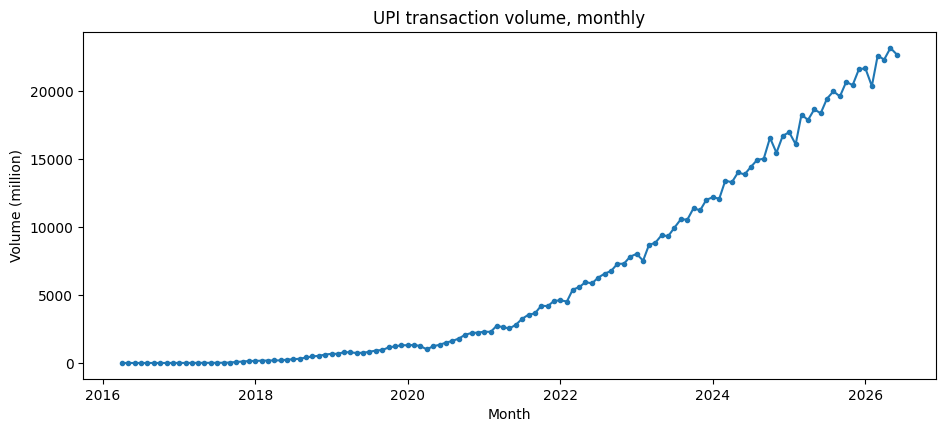

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(df["Month"], df["volume_mn"], marker="o", markersize=3)
ax.set_title("UPI transaction volume, monthly")
ax.set_xlabel("Month"); ax.set_ylabel("Volume (million)")
plt.show()

**Observation 1.** Volume rises over the whole period with no sustained decline. Individual months do fall (the smallest month-on-month change is about −20%), but they are brief dips inside a strong upward path.

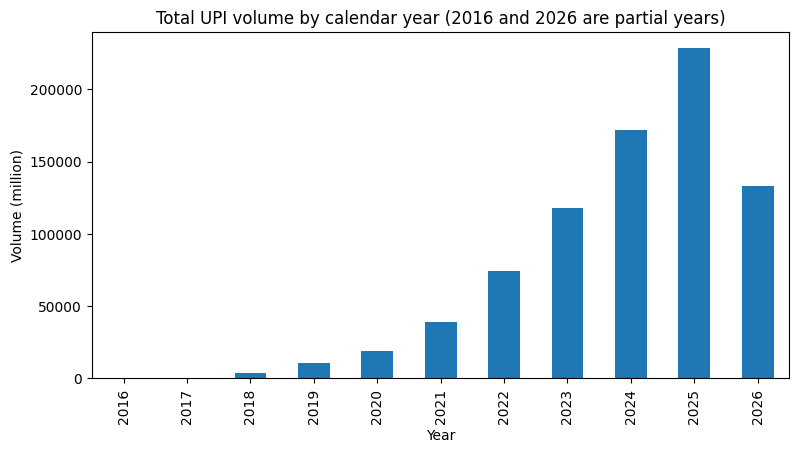

In [ ]:
annual = df.groupby("year")["volume_mn"].sum()
fig, ax = plt.subplots(figsize=(9, 4.5))
annual.plot.bar(ax=ax)
ax.set_title("Total UPI volume by calendar year (2016 and 2026 are partial years)")
ax.set_xlabel("Year"); ax.set_ylabel("Volume (million)")
plt.show()

**Observation 2.** Annual totals roughly multiply several times over between the early years and recent years. 2016 (Apr–Dec) and 2026 (Jan–Jun) cover fewer than 12 months, so their bars are not comparable with full years.

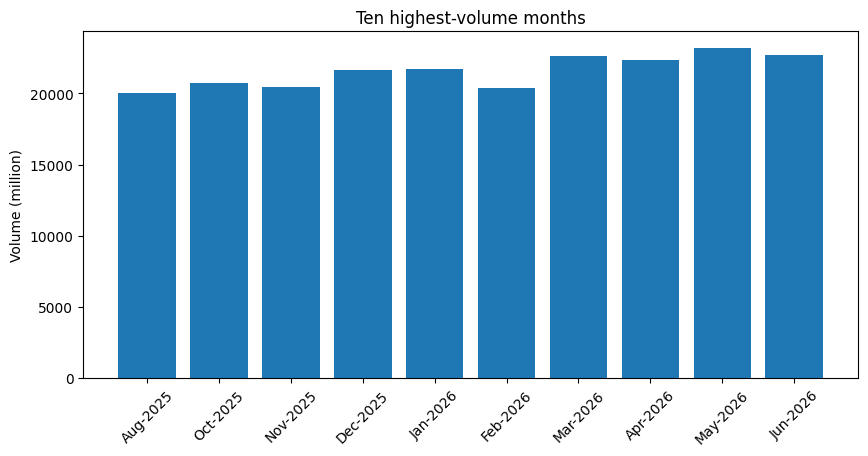

In [ ]:
top10 = df.nlargest(10, "volume_mn").sort_values("Month")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(top10["Month"].dt.strftime("%b-%Y"), top10["volume_mn"])
ax.set_title("Ten highest-volume months")
ax.set_ylabel("Volume (million)")
plt.xticks(rotation=45)
plt.show()

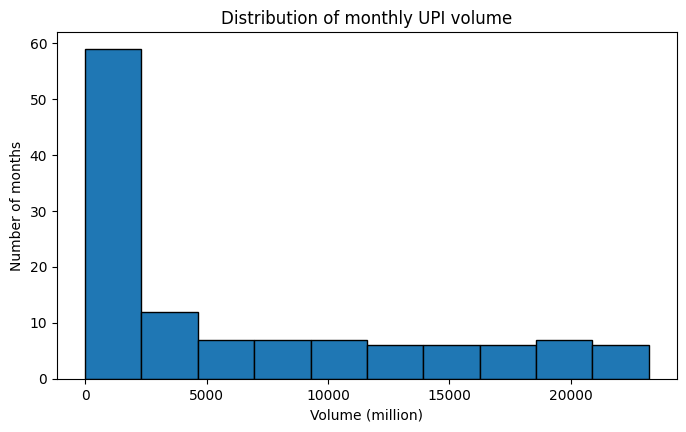

Months in the lowest bin: 59 of 123 (volume up to 2,320 million)


In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(df["volume_mn"], bins=10, edgecolor="black")
ax.set_title("Distribution of monthly UPI volume")
ax.set_xlabel("Volume (million)"); ax.set_ylabel("Number of months")
plt.show()

counts, edges = np.histogram(df["volume_mn"], bins=10)
print("Months in the lowest bin:", counts[0], "of", len(df),
      f"(volume up to {edges[1]:,.0f} million)")

**Observation 3.** The distribution is strongly right-skewed. Roughly half of all months (59 of 123 in the lowest of ten bins) fall at the low end of the range, and the higher bins hold fewer months each. This is because UPI spent its early years at small volumes before scaling up, not because high volumes are the norm. Mean volume is therefore well above the median.

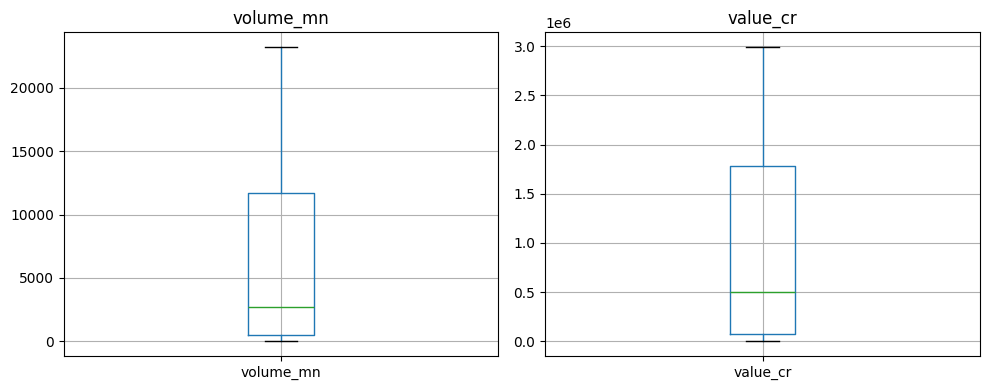

volume_mn: 0 observations flagged by the 1.5×IQR rule
value_cr: 0 observations flagged by the 1.5×IQR rule


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
df.boxplot(column="volume_mn", ax=axes[0]); axes[0].set_title("volume_mn")
df.boxplot(column="value_cr", ax=axes[1]);  axes[1].set_title("value_cr")
plt.tight_layout(); plt.show()

# IQR rule
for col in ["volume_mn", "value_cr"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    flagged = df[(df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)]
    print(f"{col}: {len(flagged)} observations flagged by the 1.5×IQR rule")

,banks_live,volume_mn,value_cr
banks_live,1.000,0.980,0.991
volume_mn,0.980,1.000,0.994
value_cr,0.991,0.994,1.000


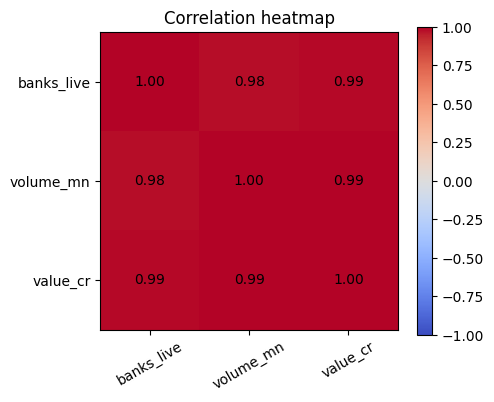

In [ ]:
corr = df[num_cols].corr()
display(corr.round(3))

fig, ax = plt.subplots(figsize=(4.8, 4))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(3)); ax.set_xticklabels(num_cols, rotation=30)
ax.set_yticks(range(3)); ax.set_yticklabels(num_cols)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im); ax.set_title("Correlation heatmap")
plt.show()

**Observation 4.** Banks live, volume and value are all correlated at about 0.98–0.99. All three trend upward over time, so a high correlation here mostly reflects a shared trend. It is not evidence that more banks *cause* more transactions.

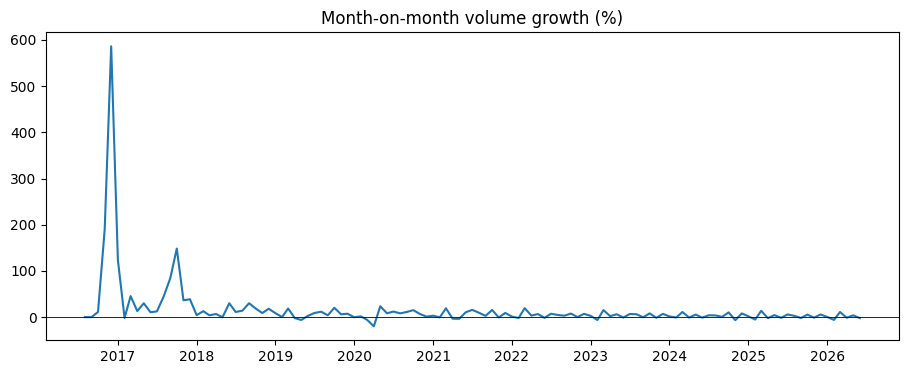

In [ ]:
g = df.loc[df["volume_mn"] > 0, ["Month", "volume_growth_pct"]].dropna()
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(g["Month"], g["volume_growth_pct"])
ax.axhline(0, color="k", lw=0.6)
ax.set_title("Month-on-month volume growth (%)")
plt.show()

**Observation 5.** Percentage growth is very high and volatile in the first months of UPI and settles at a much lower level later. Absolute monthly increases are still larger in recent years because the base is far bigger. Quantified by sub-period in Section 9.

## 4. Feature engineering and modelling dataset

**Variable selection**

| Variable | Type | Role | Selected? | Reason |
|---|---|---|---|---|
| volume_mn | Numerical | Target | Yes | Main outcome of the study |
| volume_lag_1, 2, 3, 6, 12 | Numerical | Predictors | Yes | Volume is strongly autocorrelated; lags 6 and 12 allow for half-year and annual patterns |
| month_num | Numerical | Predictor | Yes | Calendar position, allows for seasonality |
| log_volume | Numerical | Transformed target | Yes (ARIMA) | Converts multiplicative growth into additive growth |
| banks_live | Numerical | Descriptive | No | Not known in advance for future months, so it cannot support a genuine forecast |
| year | Numerical | Descriptive | No | Mostly a time index, and the lags already carry the trend |
| value_cr | Numerical | Secondary outcome | No | Near-collinear with volume (r ≈ 0.99); would be circular as a predictor |
| volume_growth_pct | Numerical | Derived | No | Computed from the target, so it leaks target information |

In [ ]:
df["log_volume"] = np.log1p(df["volume_mn"])      # log(1+x), safe at the zero launch month

LAGS = [1, 2, 3, 6, 12]
for k in LAGS:
    df[f"volume_lag_{k}"] = df["volume_mn"].shift(k)

lag_cols = [f"volume_lag_{k}" for k in LAGS]
df_model = df.dropna(subset=lag_cols).reset_index(drop=True)    # drops first 12 months

FEATURES = lag_cols + ["month_num"]
X = df_model[FEATURES]
y = df_model["volume_mn"]

# Chronological split: last 12 months are the test set
HORIZON = 12
split_point = len(df_model) - HORIZON
X_train, X_test = X.iloc[:split_point], X.iloc[split_point:]
y_train, y_test = y.iloc[:split_point], y.iloc[split_point:]

print("Modelling dataset:", df_model.shape, "|", df_model["Month"].min().strftime("%b-%Y"),
      "to", df_model["Month"].max().strftime("%b-%Y"))
print("Train:", X_train.shape, "|", df_model["Month"].iloc[0].strftime("%b-%Y"), "to",
      df_model["Month"].iloc[split_point - 1].strftime("%b-%Y"))
print("Test: ", X_test.shape, "|", df_model["Month"].iloc[split_point].strftime("%b-%Y"), "to",
      df_model["Month"].iloc[-1].strftime("%b-%Y"))

Modelling dataset: (111, 13) | Apr-2017 to Jun-2026
Train: (99, 6) | Apr-2017 to Jun-2025
Test:  (12, 6) | Jul-2025 to Jun-2026


**Preprocessing notes.** There are no categorical variables, so no encoding is needed. Scaling is not applied because the models used here (exponential smoothing, ARIMA on logs, ordinary least squares) do not depend on feature scale. The split is chronological because random splitting would let the model learn from months after the ones it is asked to predict.

**Modelling plan.** Benchmarks: Naive, Simple Exponential Smoothing (SES), Holt linear trend and Holt damped trend. Comparison models: lag-based Linear Regression and ARIMA. Metrics: MAE, RMSE and MAPE. MAE and RMSE are in millions of transactions, which can be explained to a non-technical audience, and MAPE puts errors on a scale that stays comparable as volumes grow.

## 5. Stationarity checks (training data only)

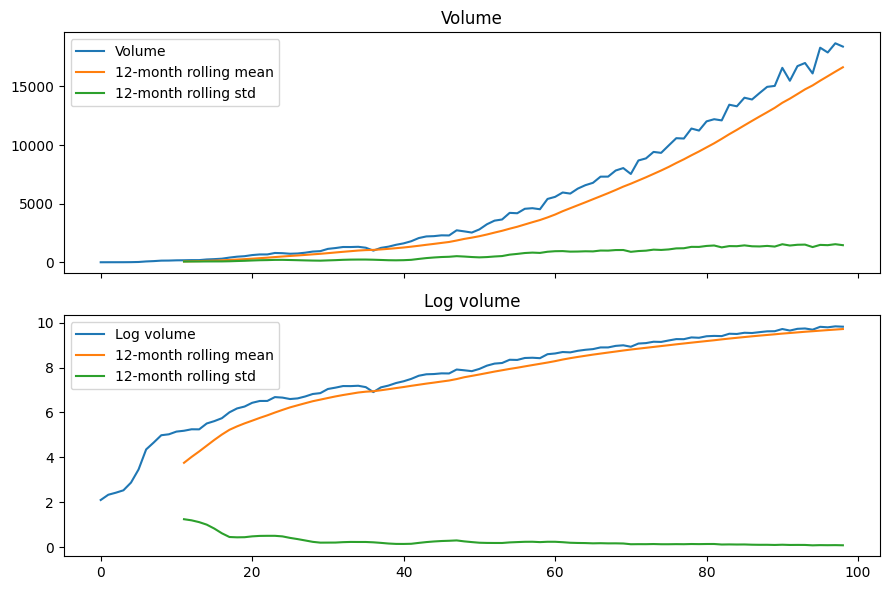

In [ ]:
vol_train = y_train
logvol_train = df_model["log_volume"].iloc[:split_point]

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for ax, s, title in zip(axes, [vol_train, logvol_train], ["Volume", "Log volume"]):
    ax.plot(s.values, label=title)
    ax.plot(s.rolling(12).mean().values, label="12-month rolling mean")
    ax.plot(s.rolling(12).std().values, label="12-month rolling std")
    ax.legend(); ax.set_title(title)
plt.tight_layout(); plt.show()

In [ ]:
def run_adf(series, name, regression="c"):
    stat, pval, lags, nobs, crit, _ = adfuller(series.dropna(), regression=regression, autolag="AIC")
    return {"Series": name, "Test setting": "constant" if regression == "c" else "constant + trend",
            "ADF stat": round(stat, 3), "p-value": round(pval, 4), "Lags": lags,
            "Conclusion": "stationary" if pval < 0.05 else "non-stationary"}

adf_table = pd.DataFrame([
    run_adf(vol_train, "Volume (level)"),
    run_adf(logvol_train, "Log volume (level)"),
    run_adf(vol_train.diff(), "Volume, 1st difference"),
    run_adf(logvol_train.diff(), "Log volume, 1st difference"),
    run_adf(vol_train, "Volume (level)", "ct"),
    run_adf(logvol_train, "Log volume (level)", "ct"),
])
display(adf_table)

,Series,Test setting,ADF stat,p-value,Lags,Conclusion
0,Volume (level),constant,-0.515,0.8892,12,non-stationary
1,Log volume (level),constant,-1.754,0.4037,12,non-stationary
2,"Volume, 1st difference",constant,-0.296,0.9261,11,non-stationary
3,"Log volume, 1st difference",constant,-3.847,0.0025,12,stationary
4,Volume (level),constant + trend,-1.114,0.9267,12,non-stationary
5,Log volume (level),constant + trend,-1.340,0.8776,12,non-stationary


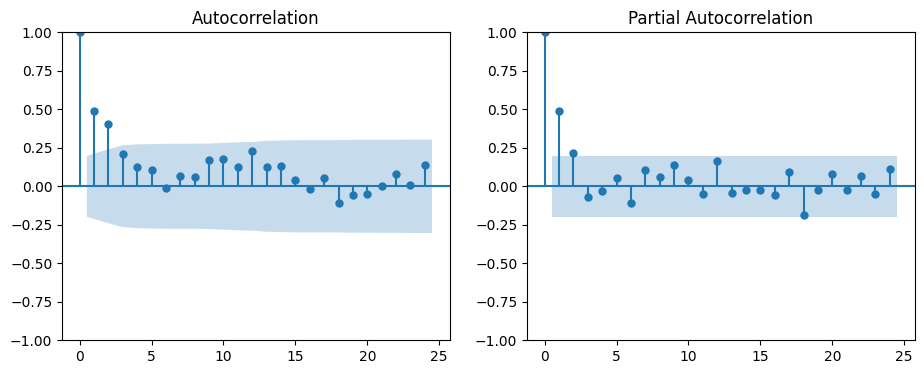

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_acf(logvol_train.diff().dropna(), lags=24, ax=axes[0])
plot_pacf(logvol_train.diff().dropna(), lags=24, ax=axes[1])
plt.show()

### Interpretation: Stationarity and ADF Test

The Augmented Dickey–Fuller (ADF) test was conducted to determine whether the UPI transaction volume series is stationary. The null hypothesis (\(H_0\)) of the ADF test states that the series contains a unit root and is therefore non-stationary. At the 5% significance level, a p-value below 0.05 leads to rejection of the null hypothesis.

The results show that the original transaction volume series is non-stationary, with a p-value of 0.8892. The log-transformed volume series is also non-stationary, with a p-value of 0.4037. Therefore, taking the logarithm alone does not make the series stationary. The first difference of the original volume series remains non-stationary, with a p-value of 0.9261. However, the first difference of log volume is stationary, with an ADF statistic of −3.847 and a p-value of 0.0025. Since this p-value is below 0.05, the null hypothesis is rejected for this transformed series.

These results suggest that the log-transformed series must be differenced once to achieve stationarity. This supports using \(d=1\) in the ARIMA model. Economically, the first difference of log volume approximates the monthly percentage growth rate of UPI transactions, allowing the model to focus on changes in transaction volume rather than its long-term upward trend.

The ACF and PACF plots of the differenced log-volume series show a strong autocorrelation at the first lag, while most subsequent lags are relatively small. This suggests that recent changes in transaction volume may help explain current changes, although the plots alone do not determine the final ARIMA order. The model must also be evaluated using information criteria, residual diagnostics and out-of-sample forecasting performance.

## 6. Forecasting functions

Every model is a function `f(y_train, X_train, X_test)` that returns forecasts for the whole test window made **from the end of the training data**, without seeing any test-period actuals. The same functions are used for the single split and the rolling-origin evaluation, so the two are consistent.

In [ ]:
def evaluate(name, actual, pred):
    actual, pred = np.asarray(actual, float), np.asarray(pred, float)
    return {"Model": name,
            "MAE": mean_absolute_error(actual, pred),
            "RMSE": float(np.sqrt(mean_squared_error(actual, pred))),
            "MAPE (%)": float(np.mean(np.abs((actual - pred) / actual)) * 100)}


def f_naive(y_tr, X_tr, X_te):
    return np.repeat(y_tr.iloc[-1], len(X_te))


def f_ses(y_tr, X_tr, X_te):
    fit = SimpleExpSmoothing(y_tr.values, initialization_method="estimated").fit()
    return np.asarray(fit.forecast(len(X_te)))


def f_holt(y_tr, X_tr, X_te):
    fit = Holt(y_tr.values, initialization_method="estimated").fit()
    return np.asarray(fit.forecast(len(X_te)))


def f_holt_damped(y_tr, X_tr, X_te):
    fit = Holt(y_tr.values, damped_trend=True, initialization_method="estimated").fit()
    return np.asarray(fit.forecast(len(X_te)))


def recursive_forecast(model, X_te, y_tr, cols):
    """Multi-step forecast. EVERY lag is rebuilt from the model's own history
    (actuals up to the forecast origin, then its own predictions), so nothing from
    the test period is used. month_num is a calendar fact and is taken from X_te."""
    hist = list(y_tr.values)
    preds = []
    for i in range(len(X_te)):
        row = {}
        for c in cols:
            if c.startswith("volume_lag_"):
                row[c] = hist[-int(c.split("_")[-1])]       # lag k = k-th most recent value
            else:
                row[c] = X_te.iloc[i][c]
        p = model.predict(pd.DataFrame([row])[list(cols)])[0]
        preds.append(p)
        hist.append(p)                                       # feed the prediction forward
    return np.array(preds)


def f_lr(y_tr, X_tr, X_te):
    m = LinearRegression().fit(X_tr, y_tr)
    return recursive_forecast(m, X_te, y_tr, X_tr.columns)


def make_f_arima(order, window=None):
    """ARIMA on log1p(volume) with drift; optionally fitted on the last `window` months only."""
    def f(y_tr, X_tr, X_te):
        s = y_tr if window is None else y_tr.iloc[-window:]
        fit = ARIMA(np.log1p(s.values), order=order, trend="t").fit()
        return np.expm1(fit.forecast(len(X_te)))
    return f

In [ ]:
# Leakage test: a genuine multi-step forecast must not depend on the lag columns of the test set.
m_test = LinearRegression().fit(X_train, y_train)
X_tampered = X_test.copy()
X_tampered[lag_cols] = X_tampered[lag_cols] * 100          # corrupt every test-period lag
a = recursive_forecast(m_test, X_test, y_train, X_train.columns)
b = recursive_forecast(m_test, X_tampered, y_train, X_train.columns)
print("Recursive forecast independent of test-period lags:", np.allclose(a, b))

Recursive forecast independent of test-period lags: True


## 7. Baseline models (single split)

In [ ]:
preds = {}
preds["Naive"] = f_naive(y_train, X_train, X_test)
preds["SES"] = f_ses(y_train, X_train, X_test)
preds["Holt"] = f_holt(y_train, X_train, X_test)
preds["Holt damped"] = f_holt_damped(y_train, X_train, X_test)

print("Last training value (naive forecast):", round(float(y_train.iloc[-1]), 2))
print("SES forecast (flat):", round(float(preds["SES"][0]), 2))
results_single = pd.DataFrame([evaluate(n, y_test, p) for n, p in preds.items()]).round(2)
display(results_single)

Last training value (naive forecast): 18395.01
SES forecast (flat): 18419.45


,Model,MAE,RMSE,MAPE (%)
0,Naive,2847.97,3105.90,13.11
1,SES,2823.54,3083.51,13.00
2,Holt,468.49,559.27,2.22
3,Holt damped,484.99,577.75,2.29


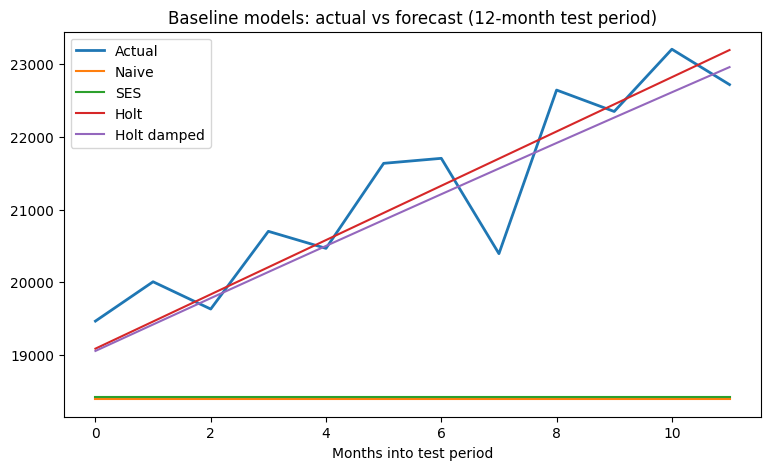

In [ ]:
x = range(len(y_test))
plt.plot(x, y_test.values, label="Actual", linewidth=2)
for n, p in preds.items():
    plt.plot(x, p, label=n)
plt.legend(); plt.xlabel("Months into test period")
plt.title("Baseline models: actual vs forecast (12-month test period)")
plt.show()

### Interpretation: Baseline Forecasting Models

Four baseline forecasting models were compared using the final 12 months of data: Naive, Simple Exponential Smoothing (SES), Holt's linear trend method, and Damped Holt. Their performance was evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Mean Absolute Percentage Error (MAPE). Lower values indicate better forecasting accuracy.

Holt's linear trend model performed best, with an MAE of 468.49, RMSE of 559.27, and MAPE of 2.22%. Damped Holt was the second-best model, with an MAE of 484.99, RMSE of 577.75, and MAPE of 2.29%. Both models performed substantially better than Naive and SES. The Naive model recorded an MAE of 2,847.97 and MAPE of 13.11%, while SES recorded an MAE of 2,823.54 and MAPE of 13.00%.

Naive and SES produce almost flat forecasts because they do not explicitly model the upward trend in UPI transaction volume. The Naive model repeats the last observed value, while SES smooths historical observations and generates a constant forecast across the forecast horizon. In contrast, Holt's method estimates both the current level and the trend, allowing its forecasts to follow the continuing increase in transaction volume. Damped Holt gradually reduces the projected trend over time, but this adjustment provides no improvement over ordinary Holt in this particular test period.

The actual-versus-forecast plot supports these results. Holt and Damped Holt follow the upward movement in transaction volume, although neither captures every month-to-month fluctuation. The Naive and SES forecasts remain nearly horizontal and fail to reflect the overall growth pattern.

However, these benchmark models have limitations. First, Naive and SES cannot adequately represent a sustained upward trend. Second, Holt and Damped Holt extrapolate a trend and may perform poorly if growth patterns change suddenly. Third, the evaluation uses only one 12-month test period, so the best-performing model on this split is not necessarily the most reliable across different forecast periods. Therefore, the models must also be compared using rolling-origin evaluation before selecting the final forecasting approach.

## 8. Linear regression with lag variables

In [ ]:
lr = LinearRegression().fit(X_train, y_train)

preds["Linear Reg. (1-step-ahead)"] = lr.predict(X_test)      # sees real lags: NOT comparable to multi-step models
preds["Linear Reg. (recursive)"] = f_lr(y_train, X_train, X_test)

results_single = pd.DataFrame([evaluate(n, y_test, p) for n, p in preds.items()]).round(2)
display(results_single)
print("Note: the 1-step-ahead row uses real lagged values at every step, so it is an easier task "
      "and should only be compared with other 1-step forecasts.")

,Model,MAE,RMSE,MAPE (%)
0,Naive,2847.97,3105.90,13.11
1,SES,2823.54,3083.51,13.00
2,Holt,468.49,559.27,2.22
3,Holt damped,484.99,577.75,2.29
4,Linear Reg. (1-step-ahead),425.66,618.76,2.03
5,Linear Reg. (recursive),1529.98,1892.80,7.01


Note: the 1-step-ahead row uses real lagged values at every step, so it is an easier task and should only be compared with other 1-step forecasts.


In [ ]:
ols = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(ols.summary())

Xc = sm.add_constant(X_train)
vif = pd.DataFrame({"feature": Xc.columns,
                    "VIF": [variance_inflation_factor(Xc.values, i) for i in range(Xc.shape[1])]})
display(vif.round(1))

                            OLS Regression Results                            
Dep. Variable:              volume_mn   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.997
Method:                 Least Squares   F-statistic:                     6515.
Date:                Sun, 11 Oct 2026   Prob (F-statistic):          1.27e-118
Time:                        05:53:21   Log-Likelihood:                -697.16
No. Observations:                  99   AIC:                             1408.
Df Residuals:                      92   BIC:                             1426.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const            28.5326     75.669      0.377

,feature,VIF
0,const,1.0
1,volume_lag_1,470.8
2,volume_lag_2,247.6
3,volume_lag_3,417.8
4,volume_lag_6,461.7
5,volume_lag_12,169.4
6,month_num,1.1


In [ ]:
variants = {
    "lag 1 only": ["volume_lag_1"],
    "lags 1-2": ["volume_lag_1", "volume_lag_2"],
    "no lags (banks, year, month)": None,
    "full": FEATURES,
}
rows = []
for name, cols in variants.items():
    if cols is None:
        tr_X, te_X = df_model[["banks_live", "year", "month_num"]].iloc[:split_point], \
                     df_model[["banks_live", "year", "month_num"]].iloc[split_point:]
    else:
        tr_X, te_X = X_train[cols], X_test[cols]
    m = LinearRegression().fit(tr_X, y_train)
    rows.append(evaluate(f"1-step: {name}", y_test, m.predict(te_X)))
display(pd.DataFrame(rows).round(2))

,Model,MAE,RMSE,MAPE (%)
0,1-step: lag 1 only,813.38,953.76,3.82
1,1-step: lags 1-2,514.26,778.27,2.45
2,"1-step: no lags (banks, year, month)",3990.25,4119.50,18.58
3,1-step: full,425.66,618.76,2.03


### Interpretation of Linear Regression Results

The linear regression model using lagged UPI transaction volume achieved an \(R^2\) of 0.998 and an adjusted \(R^2\) of 0.997, indicating that the model explains a very high proportion of the variation in transaction volume within the training data. However, this high \(R^2\) should be interpreted cautiously because the data form a time series and the lagged variables are highly correlated.

The Variance Inflation Factor (VIF) results confirm severe multicollinearity. The VIF values for lag 1, lag 2, lag 3, lag 6 and lag 12 are approximately 470.8, 247.8, 417.8, 461.7 and 169.4, respectively. These values indicate that the lagged predictors contain substantial overlapping information. Consequently, individual regression coefficients may be unstable and should not be interpreted independently as measures of economic influence.

The one-step-ahead comparison shows that the full linear regression model achieved the lowest RMSE of 618.78 and MAPE of 2.03% among the four specifications tested. It performed better than the models using only lag 1, lags 1–2, or no lagged variables. This suggests that including additional lagged information improved one-step-ahead predictive accuracy in this evaluation.

However, one-step-ahead and recursive forecasts are different. In one-step forecasting, actual observed values can be used to construct lagged predictors for subsequent test observations. In recursive forecasting, predicted values are fed back into the model to forecast further into the future, allowing errors to accumulate. Therefore, the one-step-ahead results should not be directly compared with recursive rolling-origin results as though they were identical evaluation settings.

Overall, the regression results demonstrate strong predictive performance in the one-step evaluation, but the high \(R^2\) does not by itself establish that the model will forecast reliably over longer horizons. Rolling-origin evaluation provides a more useful assessment of its performance on unseen periods.

## 9. ARIMA

In [ ]:
log_train = logvol_train.values
D = 1                                                  # from the ADF results

rows = []
for p, q in itertools.product(range(0, 4), range(0, 4)):
    try:
        fit = ARIMA(log_train, order=(p, D, q), trend="t").fit()
        rows.append({"order": (p, D, q), "AIC": fit.aic, "BIC": fit.bic})
    except Exception:
        continue
grid = pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)
display(grid.head(8).round(2))

best_order = grid.loc[0, "order"]
arima = ARIMA(log_train, order=best_order, trend="t").fit()
print("Chosen order:", best_order)
print(arima.summary().tables[1])
print("Drift per month on the log scale:", round(float(arima.params[0]), 4),
      "(about", round(float(np.expm1(arima.params[0]) * 100), 1), "% per month)")

,order,AIC,BIC
0,"(2, 1, 0)",-142.66,-132.32
1,"(1, 1, 1)",-141.39,-131.05
2,"(3, 1, 0)",-141.09,-128.17
3,"(1, 1, 3)",-141.04,-125.53
4,"(1, 1, 2)",-141.03,-128.10
5,"(2, 1, 1)",-140.96,-128.03
6,"(0, 1, 2)",-140.71,-130.37
7,"(0, 1, 3)",-140.15,-127.22


Chosen order: (2, 1, 0)
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.0795      0.036      2.218      0.027       0.009       0.150
ar.L1          0.3839      0.111      3.470      0.001       0.167       0.601
ar.L2          0.2158      0.179      1.207      0.227      -0.135       0.566
sigma2         0.0125      0.001      8.695      0.000       0.010       0.015
Drift per month on the log scale: 0.0795 (about 8.3 % per month)


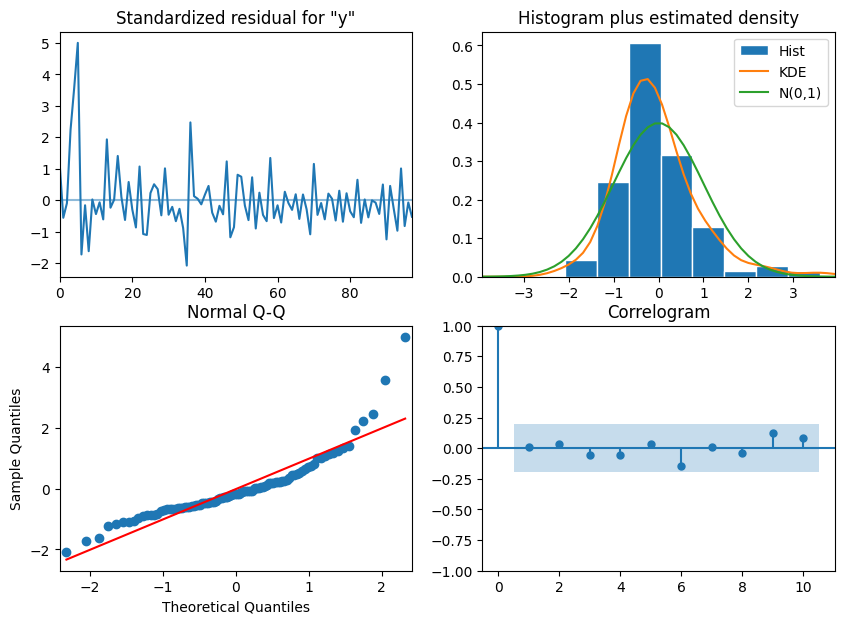

     lb_stat  lb_pvalue
6   3.200828   0.783252
12  9.901137   0.624634


In [ ]:
arima.plot_diagnostics(figsize=(10, 7))
plt.show()
print(acorr_ljungbox(arima.resid[1:], lags=[6, 12], return_df=True))

In [ ]:
# Full-history ARIMA vs ARIMA fitted on recent windows only
f_arima_full = make_f_arima(best_order)
f_arima_48 = make_f_arima(best_order, 48)
f_arima_36 = make_f_arima(best_order, 36)

preds["ARIMA (full history)"] = f_arima_full(y_train, X_train, X_test)
preds["ARIMA (last 48m)"] = f_arima_48(y_train, X_train, X_test)
preds["ARIMA (last 36m)"] = f_arima_36(y_train, X_train, X_test)

for w in (48, 36):
    s = ARIMA(np.log1p(y_train.iloc[-w:].values), order=best_order, trend="t").fit()
    print(f"Drift when fitted on last {w} months: {s.params[0]:.4f} "
          f"(~{np.expm1(s.params[0]) * 100:.1f}% per month)")

# Seasonal variant, evaluated on the same test window
sar = ARIMA(log_train, order=best_order, seasonal_order=(1, 0, 0, 12), trend="t").fit()
preds["SARIMA (seasonal AR 12)"] = np.expm1(sar.forecast(len(y_test)))
print("AIC  ARIMA:", round(arima.aic, 2), "| SARIMA:", round(sar.aic, 2))

results_single = pd.DataFrame([evaluate(n, y_test, p) for n, p in preds.items()]).round(2)
display(results_single)


def make_f_arima_auto(window=None):
    """Select ARIMA order using only data available at each forecast origin."""

    def f(y_tr, X_tr, X_te):
        # Use only the training data available at this origin
        s = y_tr if window is None else y_tr.iloc[-window:]
        log_s = np.log1p(s.values)

        # Select the best order using AIC on this training window only
        candidates = []

        for p, q in itertools.product(range(0, 4), range(0, 4)):
            try:
                fit = ARIMA(
                    log_s,
                    order=(p, 1, q),
                    trend="t"
                ).fit()

                candidates.append((fit.aic, (p, 1, q)))
            except Exception:
                continue

        if not candidates:
            raise ValueError("No ARIMA candidate fitted successfully.")

        best_aic, selected_order = min(candidates, key=lambda x: x[0])

        # Refit using the selected order and forecast the next horizon
        final_fit = ARIMA(
            log_s,
            order=selected_order,
            trend="t"
        ).fit()

        return np.expm1(final_fit.forecast(len(X_te)))

    return f

Drift when fitted on last 48 months: 0.0369 (~3.8% per month)
Drift when fitted on last 36 months: 0.0311 (~3.2% per month)
AIC  ARIMA: -142.66 | SARIMA: -147.16


,Model,MAE,RMSE,MAPE (%)
0,Naive,2847.97,3105.90,13.11
1,SES,2823.54,3083.51,13.00
2,Holt,468.49,559.27,2.22
3,Holt damped,484.99,577.75,2.29
4,Linear Reg. (1-step-ahead),425.66,618.76,2.03
5,Linear Reg. (recursive),1529.98,1892.80,7.01
6,ARIMA (full history),6744.68,8834.51,30.55
7,ARIMA (last 48m),2875.78,3500.84,13.17
8,ARIMA (last 36m),1981.34,2447.77,9.09
9,SARIMA (seasonal AR 12),5533.61,7085.45,25.09


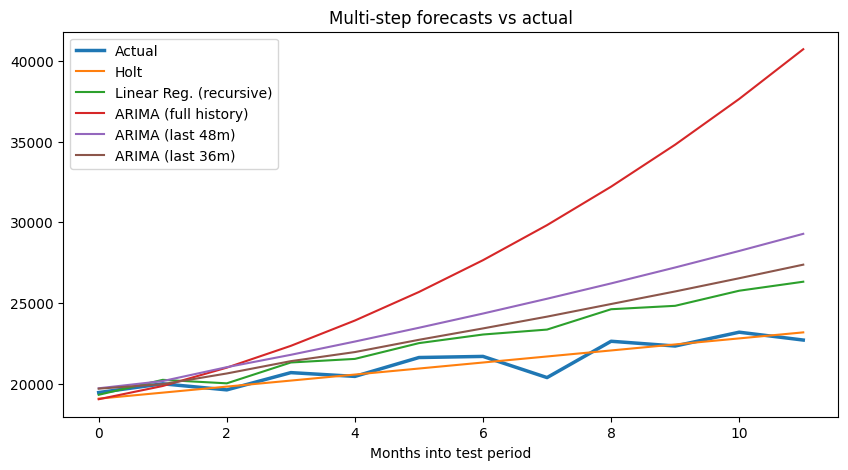

In [ ]:
x = range(len(y_test))
plt.figure(figsize=(10, 5))
plt.plot(x, y_test.values, label="Actual", linewidth=2.5)
for n in ["Holt", "Linear Reg. (recursive)", "ARIMA (full history)", "ARIMA (last 48m)", "ARIMA (last 36m)"]:
    plt.plot(x, preds[n], label=n)
plt.legend(); plt.xlabel("Months into test period")
plt.title("Multi-step forecasts vs actual")
plt.show()

### Interpretation of ARIMA and Multi-Step Forecast Results

The ARIMA model order was selected by comparing candidate models using AIC, while stationarity tests and ACF/PACF plots helped guide the modelling process. The log-transformed transaction-volume series became stationary after first differencing, supporting the use of \(d=1\). However, the screenshot does not show the selected order or the AIC comparison table, so the exact ARIMA order and its supporting evidence should be reported from those outputs.

The drift coefficient represents the average trend in the differenced log transaction-volume series. In this model, a positive drift indicates an upward trend in transaction volume, while a negative drift indicates a downward trend. Because the model uses log-transformed data, the drift is approximately related to the percentage change per month. Its statistical significance should be checked before drawing a firm conclusion.

The multi-step forecast comparison shows that the full-history ARIMA model produces a much steeper upward forecast than the other models and substantially overshoots the actual transaction volumes toward the end of the test period. Its reported RMSE is 8,834.51 and MAPE is 30.55%, indicating relatively weak performance on this holdout. This suggests that extrapolating the trend estimated from the full training history may not capture the more recent growth pattern well.

The seasonal ARIMA (SARIMA) model has a reported RMSE of 7,085.45 and MAPE of 25.09%. Although these results are better than those of the full-history ARIMA model, its errors remain high compared with Holt's linear trend model, which has an RMSE of 559.27 and MAPE of 2.22% on the same single-split evaluation. Based on these reported metrics, the seasonal component does not appear to provide enough improvement to justify keeping SARIMA as the preferred forecasting model.

Overall, the results suggest that Holt's linear trend model provides a much closer forecast for this particular test period. The rolling-origin evaluation should still be used to assess whether this advantage remains consistent across different forecast origins and horizons.

## 10. Rolling-origin evaluation

Each model is refitted at 14 forecast origins (every 3 months) on an expanding window, and forecasts the next 12 months. The last origin is exactly the single split above, which is used as a consistency check.

In [ ]:

# ARIMA orders are reselected independently at each origin
f_arima_auto = make_f_arima_auto()
f_arima_48_auto = make_f_arima_auto(window=48)
f_arima_36_auto = make_f_arima_auto(window=36)

models = {
    "Naive": f_naive,
    "SES": f_ses,
    "Holt": f_holt,
    "Holt damped": f_holt_damped,
    "Linear Reg. (recursive)": f_lr,
    "ARIMA (reselected)": f_arima_auto,
    "ARIMA (last 48m, reselected)": f_arima_48_auto,
    "ARIMA (last 36m, reselected)": f_arima_36_auto,
}

In [ ]:

# Generate rolling-origin forecasts using the updated model functions

import warnings
warnings.filterwarnings("ignore")

# Start with 60 months of training data; advance by 3 months.
# The final origin matches the original 12-month holdout split.
origins = list(range(split_point - 39, split_point + 1, 3))

records = []

for o in origins:
    y_tr = y.iloc[:o]
    y_te = y.iloc[o:o + HORIZON]
    X_tr = X.iloc[:o]
    X_te = X.iloc[o:o + HORIZON]

    for name, fn in models.items():
        try:
            preds_origin = np.asarray(fn(y_tr, X_tr, X_te), dtype=float)

            if len(preds_origin) != len(y_te):
                raise ValueError("Forecast length does not match test window.")

            for h, (actual, pred) in enumerate(
                zip(y_te.values, preds_origin), start=1
            ):
                records.append({
                    "origin": o,
                    "model": name,
                    "h": h,
                    "actual": actual,
                    "pred": pred
                })

        except Exception as e:
            print(f"Failed: {name}, origin {o}: {e}")

long = pd.DataFrame(records)

# Recalculate forecast errors
long["err"] = long["pred"] - long["actual"]
long["abs_err"] = long["err"].abs()
long["sq_err"] = long["err"] ** 2
long["ape"] = long["abs_err"] / long["actual"] * 100

print("Origins:", len(origins), "| Expected: 14")
print("Forecast rows:", len(long), "| Expected:", len(models) * 14 * HORIZON)
print("Models evaluated:", sorted(long["model"].unique()))

Origins: 14 | Expected: 14
Forecast rows: 1344 | Expected: 1344
Models evaluated: ['ARIMA (last 36m, reselected)', 'ARIMA (last 48m, reselected)', 'ARIMA (reselected)', 'Holt', 'Holt damped', 'Linear Reg. (recursive)', 'Naive', 'SES']


ROLLING-ORIGIN MODEL COMPARISON


,model,MAE,RMSE,MAPE,Forecasts
0,Holt,452.93,566.96,3.54,168
1,Holt damped,494.30,612.93,3.85,168
2,Linear Reg. (recursive),1221.11,1507.36,9.08,168
3,"ARIMA (last 36m, reselected)",1768.52,2238.27,12.52,168
4,Naive,2304.76,2663.65,17.10,168
5,"ARIMA (last 48m, reselected)",2315.78,2926.79,16.73,168
6,SES,2325.33,2682.53,17.20,168
7,ARIMA (reselected),6791.75,8850.90,48.05,168


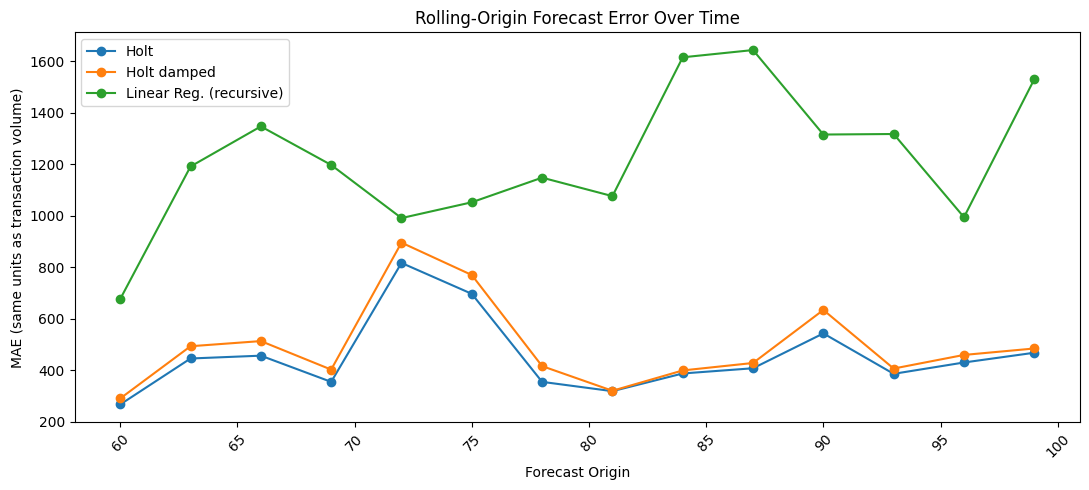

FORECAST ERROR BY HORIZON


,model,horizon_band,MAE,RMSE,MAPE,Forecasts
0,"ARIMA (last 36m, reselected)",Months 1-3,467.71,639.80,4.04,42
1,"ARIMA (last 36m, reselected)",Months 4-6,1139.78,1302.64,8.86,42
2,"ARIMA (last 36m, reselected)",Months 7-9,2108.34,2286.64,15.01,42
3,"ARIMA (last 36m, reselected)",Months 10-12,3358.26,3564.33,22.18,42
4,"ARIMA (last 48m, reselected)",Months 1-3,648.70,815.15,5.55,42
5,"ARIMA (last 48m, reselected)",Months 4-6,1505.39,1715.88,12.06,42
6,"ARIMA (last 48m, reselected)",Months 7-9,2753.83,2971.67,20.02,42
7,"ARIMA (last 48m, reselected)",Months 10-12,4355.21,4671.72,29.28,42
8,ARIMA (reselected),Months 1-3,1208.81,1594.20,10.39,42
9,ARIMA (reselected),Months 4-6,3864.56,4343.39,30.42,42


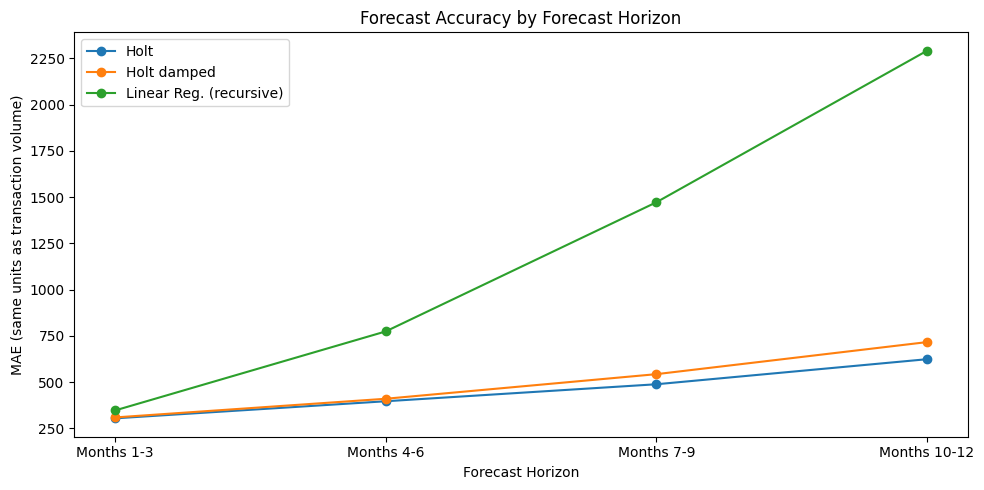

In [ ]:

# Check the columns in the existing rolling-origin results
required_cols = {"origin", "model", "h", "actual", "pred"}
missing_cols = required_cols - set(long.columns)

if missing_cols:
    raise ValueError(f"Missing columns in long: {missing_cols}")

# Recalculate error columns to ensure consistency
long = long.copy()
long["abs_err"] = (long["pred"] - long["actual"]).abs()
long["sq_err"] = (long["pred"] - long["actual"]) ** 2
long["ape"] = np.where(
    long["actual"] != 0,
    long["abs_err"] / long["actual"].abs() * 100,
    np.nan
)

# A. Overall rolling-origin performance
rolling_summary = (
    long.groupby("model")
    .agg(
        MAE=("abs_err", "mean"),
        RMSE=("sq_err", lambda x: np.sqrt(x.mean())),
        MAPE=("ape", "mean"),
        Forecasts=("pred", "count")
    )
    .sort_values("MAE")
    .reset_index()
)

print("ROLLING-ORIGIN MODEL COMPARISON")
display(rolling_summary.round(2))

# B. Error at each forecast origin
origin_errors = (
    long.groupby(["origin", "model"])
    .agg(
        MAE=("abs_err", "mean"),
        MAPE=("ape", "mean")
    )
    .reset_index()
)

# Convert origin indices to dates where possible
if isinstance(y.index, pd.DatetimeIndex):
    origin_errors["origin_date"] = origin_errors["origin"].map(
        lambda i: y.index[int(i)]
    )
else:
    origin_errors["origin_date"] = origin_errors["origin"]

# Plot MAE over time for the three models with the lowest
# overall rolling-origin MAE
top_models = rolling_summary["model"].head(3).tolist()
plot_data = origin_errors[
    origin_errors["model"].isin(top_models)
]

plt.figure(figsize=(11, 5))

for model in top_models:
    subset = plot_data[plot_data["model"] == model]
    plt.plot(
        subset["origin_date"],
        subset["MAE"],
        marker="o",
        label=model
    )

plt.title("Rolling-Origin Forecast Error Over Time")
plt.xlabel("Forecast Origin")
plt.ylabel("MAE (same units as transaction volume)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# C. Does error rise as the forecast extends further into the future?
long["horizon_band"] = pd.cut(
    long["h"],
    bins=[0, 3, 6, 9, 12],
    labels=["Months 1-3", "Months 4-6",
            "Months 7-9", "Months 10-12"]
)

horizon_summary = (
    long.groupby(["model", "horizon_band"], observed=False)
    .agg(
        MAE=("abs_err", "mean"),
        RMSE=("sq_err", lambda x: np.sqrt(x.mean())),
        MAPE=("ape", "mean"),
        Forecasts=("pred", "count")
    )
    .reset_index()
)

print("FORECAST ERROR BY HORIZON")
display(horizon_summary.round(2))

# Plot horizon-specific MAE for the same top three models
plt.figure(figsize=(10, 5))

for model in top_models:
    subset = horizon_summary[horizon_summary["model"] == model]
    plt.plot(
        subset["horizon_band"].astype(str),
        subset["MAE"],
        marker="o",
        label=model
    )

plt.title("Forecast Accuracy by Forecast Horizon")
plt.xlabel("Forecast Horizon")
plt.ylabel("MAE (same units as transaction volume)")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
# Forecast-row audit: confirm every model has a complete 12-month window at every origin
assert max(origins) + HORIZON <= len(df_model), "an origin's test window runs past the data"

expected_per_model = len(origins) * HORIZON
audit = pd.DataFrame({"rows": long.groupby("model").size()})
audit["expected"] = expected_per_model
audit["complete"] = audit["rows"] == audit["expected"]
display(audit)

win_len = long.groupby(["model", "origin"])["h"].max().unstack()
print("Models in dict:", len(models), "| models in results:", long["model"].nunique())
print("Origins:", len(origins), "| origins in results:", long["origin"].nunique())
print("Window lengths seen (max h per model and origin):", sorted(set(win_len.values.ravel())))
print("Duplicate (model, origin, h) rows:", long.duplicated(["model", "origin", "h"]).sum())
print("Total rows:", len(long), "| expected:", len(models) * len(origins) * HORIZON)
print("ALL CHECKS PASS:", bool(audit["complete"].all()) and len(long) == len(models) * len(origins) * HORIZON)

,rows,expected,complete
model,,,
"ARIMA (last 36m, reselected)",168,168,True
"ARIMA (last 48m, reselected)",168,168,True
ARIMA (reselected),168,168,True
Holt,168,168,True
Holt damped,168,168,True
Linear Reg. (recursive),168,168,True
Naive,168,168,True
SES,168,168,True


Models in dict: 8 | models in results: 8
Origins: 14 | origins in results: 14
Window lengths seen (max h per model and origin): [np.int64(12)]
Duplicate (model, origin, h) rows: 0
Total rows: 1344 | expected: 1344
ALL CHECKS PASS: True


Valid monthly observations: 120
First valid month: Jul 2016
Last valid month: Jun 2026

Recent comparison period:
Start: Jun 2021
End: Jun 2026


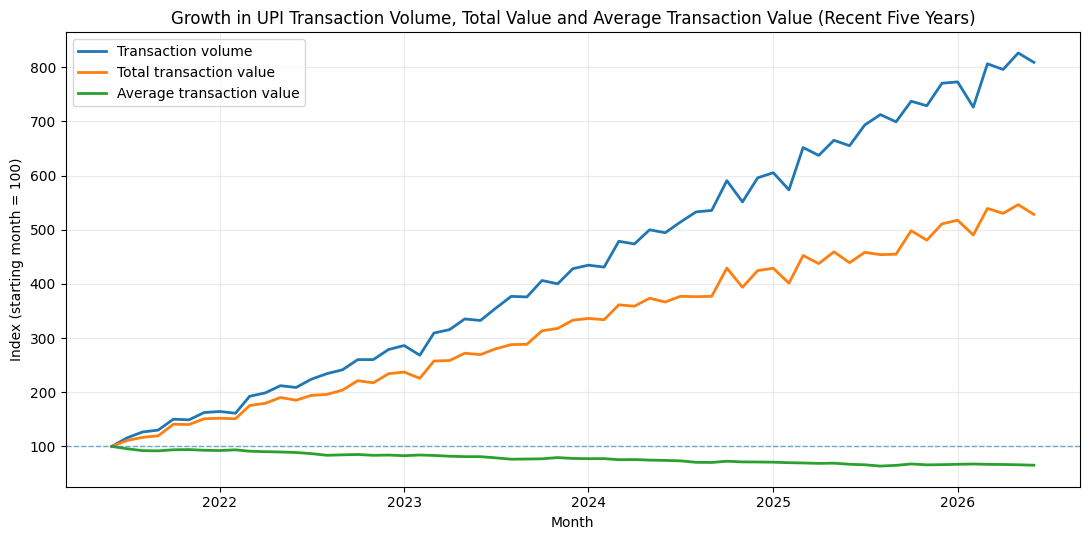


VOLUME, VALUE AND AVERAGE TRANSACTION VALUE GROWTH


,Period,Start month,End month,Volume growth (%),Total value growth (%),Average transaction value growth (%),Volume CAGR (%),Value CAGR (%),Average transaction value CAGR (%)
0,Recent five years,Jun 2021,Jun 2026,709.12,428.37,-34.7,51.92,39.51,-8.17



LATEST OBSERVATIONS


,Month,volume_mn,value_cr,avg_transaction_value_rs
114,2026-01-01,21703.44,2833481.22,1305.54
115,2026-02-01,20394.18,2684229.29,1316.17
116,2026-03-01,22641.11,2952542.05,1304.06
117,2026-04-01,22346.80,2902988.05,1299.06
118,2026-05-01,23201.93,2990424.21,1288.87
119,2026-06-01,22716.07,2892138.67,1273.17


In [ ]:
DATE_COL = "Month"
VOLUME_COL = "volume_mn"
VALUE_COL = "value_cr"
growth_df = df[[DATE_COL, VOLUME_COL, VALUE_COL]].copy()

growth_df[DATE_COL] = pd.to_datetime(
    growth_df[DATE_COL], errors="coerce"
)
growth_df[VOLUME_COL] = pd.to_numeric(
    growth_df[VOLUME_COL], errors="coerce"
)
growth_df[VALUE_COL] = pd.to_numeric(
    growth_df[VALUE_COL], errors="coerce"
)

growth_df = growth_df.replace([np.inf, -np.inf], np.nan)

growth_df = growth_df.dropna(
    subset=[DATE_COL, VOLUME_COL, VALUE_COL]
)

growth_df = growth_df[
    (growth_df[VOLUME_COL] > 0) &
    (growth_df[VALUE_COL] > 0)
].sort_values(DATE_COL).reset_index(drop=True)

growth_df["avg_transaction_value_rs"] = (
    growth_df[VALUE_COL] / growth_df[VOLUME_COL] * 10
)

growth_df = growth_df.replace([np.inf, -np.inf], np.nan)

growth_df = growth_df.dropna(
    subset=["avg_transaction_value_rs"]
)

growth_df = growth_df[
    growth_df["avg_transaction_value_rs"] > 0
].sort_values(DATE_COL).reset_index(drop=True)

print("Valid monthly observations:", len(growth_df))
print("First valid month:", growth_df[DATE_COL].min().strftime("%b %Y"))
print("Last valid month:", growth_df[DATE_COL].max().strftime("%b %Y"))

last_date = growth_df[DATE_COL].max()
target_date = last_date - pd.DateOffset(years=5)

start_idx = (
    growth_df[DATE_COL] - target_date
).abs().idxmin()

start_date = growth_df.loc[start_idx, DATE_COL]

recent_df = growth_df[
    growth_df[DATE_COL] >= start_date
].copy().reset_index(drop=True)

print("\nRecent comparison period:")
print("Start:", recent_df[DATE_COL].iloc[0].strftime("%b %Y"))
print("End:", recent_df[DATE_COL].iloc[-1].strftime("%b %Y"))

recent_df["volume_index"] = (
    recent_df[VOLUME_COL] / recent_df[VOLUME_COL].iloc[0] * 100
)

recent_df["value_index"] = (
    recent_df[VALUE_COL] / recent_df[VALUE_COL].iloc[0] * 100
)

recent_df["ticket_index"] = (
    recent_df["avg_transaction_value_rs"]
    / recent_df["avg_transaction_value_rs"].iloc[0] * 100
)

plt.figure(figsize=(11, 5.5))

plt.plot(
    recent_df[DATE_COL],
    recent_df["volume_index"],
    label="Transaction volume",
    linewidth=2
)

plt.plot(
    recent_df[DATE_COL],
    recent_df["value_index"],
    label="Total transaction value",
    linewidth=2
)

plt.plot(
    recent_df[DATE_COL],
    recent_df["ticket_index"],
    label="Average transaction value",
    linewidth=2
)

plt.axhline(
    y=100,
    linestyle="--",
    linewidth=1,
    alpha=0.6
)

plt.title(
    "Growth in UPI Transaction Volume, Total Value "
    "and Average Transaction Value (Recent Five Years)"
)

plt.xlabel("Month")
plt.ylabel("Index (starting month = 100)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

def calculate_growth(data, period_name):
    first = data.iloc[0]
    last = data.iloc[-1]

    years = (
        (last[DATE_COL] - first[DATE_COL]).days / 365.25
    )

    if years <= 0:
        raise ValueError(
            "The comparison period must cover more than zero years."
        )

    volume_ratio = last[VOLUME_COL] / first[VOLUME_COL]
    value_ratio = last[VALUE_COL] / first[VALUE_COL]

    ticket_ratio = (
        last["avg_transaction_value_rs"]
        / first["avg_transaction_value_rs"]
    )

    return {
        "Period": period_name,
        "Start month": first[DATE_COL].strftime("%b %Y"),
        "End month": last[DATE_COL].strftime("%b %Y"),

        "Volume growth (%)": (volume_ratio - 1) * 100,
        "Total value growth (%)": (value_ratio - 1) * 100,
        "Average transaction value growth (%)": (ticket_ratio - 1) * 100,

        "Volume CAGR (%)": (volume_ratio ** (1 / years) - 1) * 100,
        "Value CAGR (%)": (value_ratio ** (1 / years) - 1) * 100,
        "Average transaction value CAGR (%)": (
            ticket_ratio ** (1 / years) - 1
        ) * 100
    }

# Full sample
full_result = calculate_growth(
    growth_df,
    "Full sample"
)

# Recent five years
recent_result = calculate_growth(
    recent_df,
    "Recent five years"
)

growth_comparison = pd.DataFrame(
    [recent_result]
)

print("\nVOLUME, VALUE AND AVERAGE TRANSACTION VALUE GROWTH")
display(growth_comparison.round(2))

print("\nLATEST OBSERVATIONS")

display(
    growth_df[
        [
            DATE_COL,
            VOLUME_COL,
            VALUE_COL,
            "avg_transaction_value_rs"
        ]
    ].tail(6).round(2)
)




FORECAST ERROR AND ACTUAL GROWTH BY ORIGIN


,origin,model,MAE,MAPE,origin_date,actual_12m_volume_growth_pct
0,60,"ARIMA (last 36m, reselected)",513.27,6.80,60,76.86
1,60,"ARIMA (last 48m, reselected)",1864.61,24.98,60,76.86
2,60,ARIMA (reselected),6020.55,80.32,60,76.86
3,60,Holt,267.79,3.65,60,76.86
4,60,Holt damped,291.05,3.95,60,76.86
...,...,...,...,...,...,...
107,99,Holt,468.49,2.22,99,33.71
108,99,Holt damped,484.99,2.29,99,33.71
109,99,Linear Reg. (recursive),1529.98,7.01,99,33.71
110,99,Naive,2847.97,13.11,99,33.71


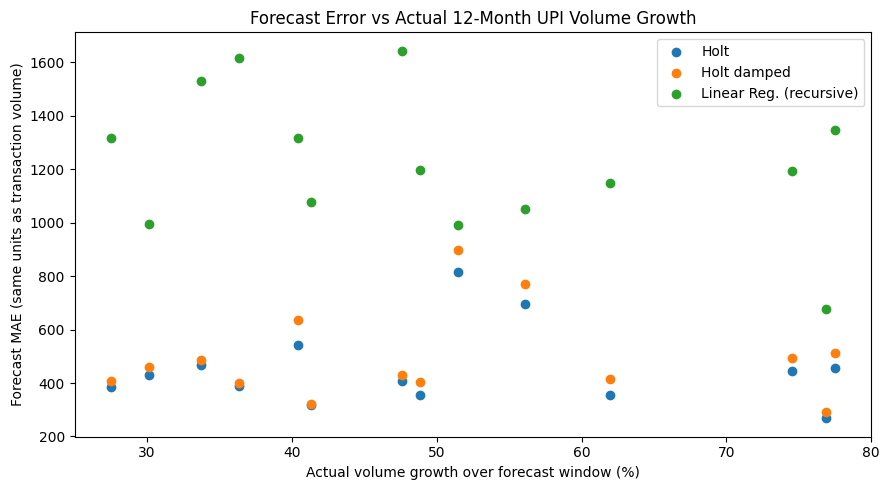

In [ ]:

# Build one row per forecast origin, using its 12-month actual
# forecast window. Uses the existing long results.
growth_lookup = growth_df.set_index(DATE_COL).sort_index()

growth_rows = []

for origin in sorted(long["origin"].unique()):
    origin = int(origin)

    # Forecast targets are origin+1 through origin+12
    target_positions = list(range(origin + 1, origin + 13))

    if max(target_positions) >= len(growth_df):
        continue

    window = growth_df.iloc[target_positions]

    if window[VOLUME_COL].iloc[0] <= 0:
        continue

    window_growth = (
        window[VOLUME_COL].iloc[-1]
        / window[VOLUME_COL].iloc[0] - 1
    ) * 100

    growth_rows.append({
        "origin": origin,
        "origin_date": growth_df[DATE_COL].iloc[origin],
        "actual_12m_volume_growth_pct": window_growth
    })

origin_growth = pd.DataFrame(growth_rows)

# Attach the actual 12-month growth to each model's forecast errors
growth_error = origin_errors.merge(
    origin_growth[["origin", "actual_12m_volume_growth_pct"]],
    on="origin",
    how="inner"
)

print("FORECAST ERROR AND ACTUAL GROWTH BY ORIGIN")
display(growth_error.round(2))

# Plot for the top three models from the rolling-origin results
plt.figure(figsize=(9, 5))

for model in top_models:
    subset = growth_error[growth_error["model"] == model]
    plt.scatter(
        subset["actual_12m_volume_growth_pct"],
        subset["MAE"],
        label=model
    )

plt.title("Forecast Error vs Actual 12-Month UPI Volume Growth")
plt.xlabel("Actual volume growth over forecast window (%)")
plt.ylabel("Forecast MAE (same units as transaction volume)")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
summary = long.groupby("model").agg(
    MAE=("abs_err", "mean"),
    RMSE=("sq_err", lambda s: np.sqrt(s.mean())),
    MAPE=("ape", "mean"),
).round(2).sort_values("RMSE")
display(summary)


# Consistency check: compare model names safely
last = origins[-1]

check = (
    long[long["origin"] == last]
    .groupby("model")
    .agg(
        MAE=("abs_err", "mean"),
        RMSE=("sq_err", lambda s: np.sqrt(s.mean())),
        MAPE=("ape", "mean")
    )
    .round(2)
)

print("Performance at the last rolling origin:")
display(check)

print("\nModels in rolling-origin results:")
print(check.index.tolist())

print("\nModels in single-split results:")
print(results_single["Model"].tolist())

# Compare only models whose names appear in both tables
ref = results_single.set_index("Model")

common_models = check.index.intersection(ref.index)

if len(common_models) == 0:
    print(
        "\nNo identical model names found. "
        "The single-split and rolling-origin results "
        "cannot be matched by name."
    )
else:
    print("\nComparison for matching model names:")
    for m in common_models:
        matches = np.isclose(
            check.loc[m, "RMSE"],
            ref.loc[m, "RMSE"],
            rtol=1e-3
        )
        print(f"{m}: RMSE matches = {matches}")


,MAE,RMSE,MAPE
model,,,
Holt,452.93,566.96,3.54
Holt damped,494.30,612.93,3.85
Linear Reg. (recursive),1221.11,1507.36,9.08
"ARIMA (last 36m, reselected)",1768.52,2238.27,12.52
Naive,2304.76,2663.65,17.10
SES,2325.33,2682.53,17.20
"ARIMA (last 48m, reselected)",2315.78,2926.79,16.73
ARIMA (reselected),6791.75,8850.90,48.05


Performance at the last rolling origin:


,MAE,RMSE,MAPE
model,,,
"ARIMA (last 36m, reselected)",1726.23,2162.59,7.89
"ARIMA (last 48m, reselected)",1127.76,1510.55,5.18
ARIMA (reselected),6744.68,8834.51,30.55
Holt,468.49,559.27,2.22
Holt damped,484.99,577.75,2.29
Linear Reg. (recursive),1529.98,1892.80,7.01
Naive,2847.97,3105.90,13.11
SES,2823.54,3083.51,13.00



Models in rolling-origin results:
['ARIMA (last 36m, reselected)', 'ARIMA (last 48m, reselected)', 'ARIMA (reselected)', 'Holt', 'Holt damped', 'Linear Reg. (recursive)', 'Naive', 'SES']

Models in single-split results:
['Naive', 'SES', 'Holt', 'Holt damped', 'Linear Reg. (1-step-ahead)', 'Linear Reg. (recursive)', 'ARIMA (full history)', 'ARIMA (last 48m)', 'ARIMA (last 36m)', 'SARIMA (seasonal AR 12)']

Comparison for matching model names:
Holt: RMSE matches = True
Holt damped: RMSE matches = True
Linear Reg. (recursive): RMSE matches = True
Naive: RMSE matches = True
SES: RMSE matches = True


h,1,3,6,12
model,,,,
"ARIMA (last 36m, reselected)",1.92,5.06,10.52,24.10
"ARIMA (last 48m, reselected)",2.85,7.67,14.13,31.99
ARIMA (reselected),5.06,15.55,38.56,105.22
Holt,1.91,2.17,3.64,4.48
Holt damped,1.95,2.24,3.80,5.31
Linear Reg. (recursive),1.54,3.53,7.48,16.97
Naive,4.32,8.73,16.76,29.07
SES,4.24,8.87,16.89,29.19


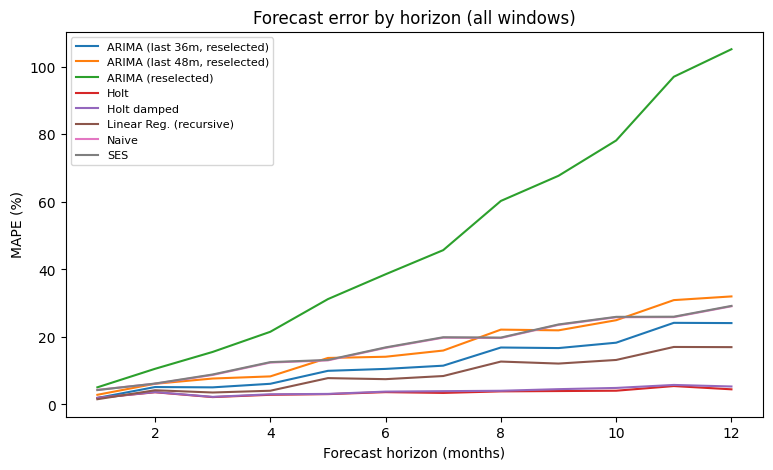

In [ ]:
by_h = long[long.h.isin([1, 3, 6, 12])].pivot_table(
    index="model", columns="h", values="ape", aggfunc="mean").round(2)
display(by_h)

plt.figure(figsize=(9, 5))
for name, d in long.groupby("model"):
    plt.plot(d.groupby("h")["ape"].mean(), label=name)
plt.xlabel("Forecast horizon (months)"); plt.ylabel("MAPE (%)")
plt.legend(fontsize=8); plt.title("Forecast error by horizon (all windows)")
plt.show()

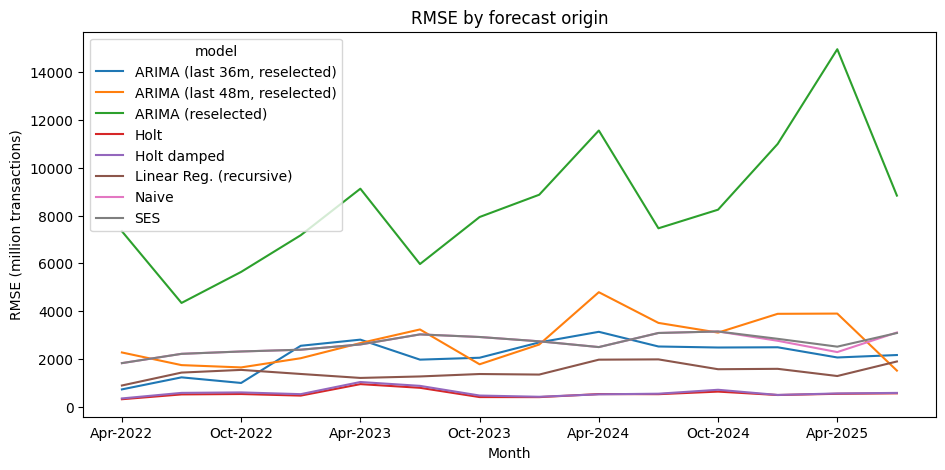

In [ ]:
per_origin = long.groupby(["origin", "model"]).apply(lambda d: np.sqrt(d.sq_err.mean())).unstack()
per_origin_plot = per_origin.copy()
per_origin_plot.index = df_model["Month"].iloc[per_origin.index].dt.strftime("%b-%Y")
per_origin_plot.plot(figsize=(11, 5), title="RMSE by forecast origin")
plt.ylabel("RMSE (million transactions)")
plt.show()

## 11. Model comparison

,Single split MAE,Single split RMSE,Single split MAPE,Rolling MAE,Rolling RMSE,Rolling MAPE,RMSE vs Naive (%),Windows won,Total windows
model,,,,,,,,,
Holt,468.49,559.27,2.22,452.93,566.96,3.54,78.7,13,14
Holt damped,484.99,577.75,2.29,494.30,612.93,3.85,77.0,1,14
Linear Reg. (recursive),1529.98,1892.80,7.01,1221.11,1507.36,9.08,43.4,0,14
"ARIMA (last 36m, reselected)",1726.23,2162.59,7.89,1768.52,2238.27,12.52,16.0,0,14
Naive,2847.97,3105.90,13.11,2304.76,2663.65,17.10,0.0,0,14
SES,2823.54,3083.51,13.00,2325.33,2682.53,17.20,-0.7,0,14
"ARIMA (last 48m, reselected)",1127.76,1510.55,5.18,2315.78,2926.79,16.73,-9.9,0,14
ARIMA (reselected),6744.68,8834.51,30.55,6791.75,8850.90,48.05,-232.3,0,14


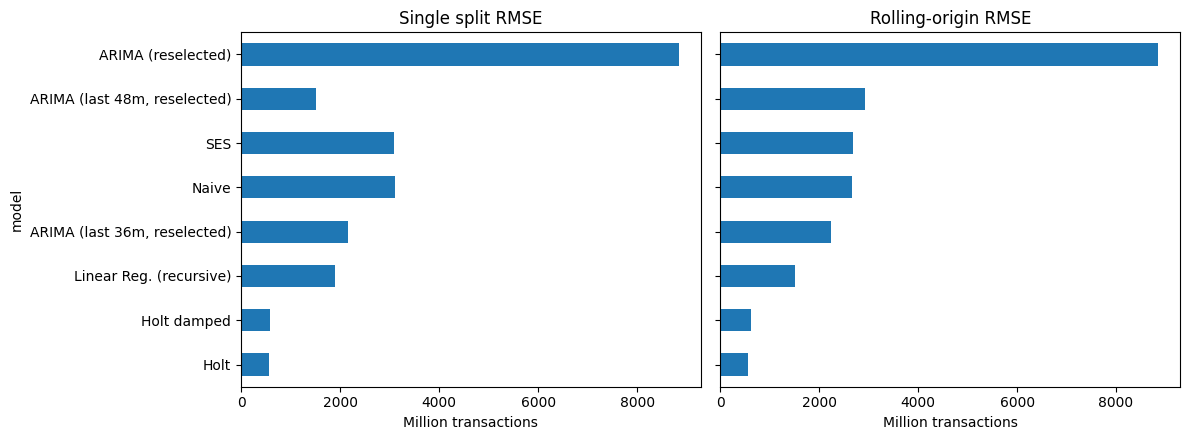

In [ ]:
single = check.add_prefix("Single split ")
rolling = summary.add_prefix("Rolling ")
comp = single.join(rolling).sort_values("Rolling RMSE")

ref_model = "Naive"
comp["RMSE vs Naive (%)"] = ((1 - comp["Rolling RMSE"] / comp.loc[ref_model, "Rolling RMSE"]) * 100).round(1)
wins = per_origin.idxmin(axis=1).value_counts()
comp["Windows won"] = wins.reindex(comp.index).fillna(0).astype(int)
comp["Total windows"] = len(per_origin)
display(comp)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
comp["Single split RMSE"].plot.barh(ax=axes[0], title="Single split RMSE")
comp["Rolling RMSE"].plot.barh(ax=axes[1], title="Rolling-origin RMSE")
for ax in axes:
    ax.set_xlabel("Million transactions")
plt.tight_layout(); plt.show()

In [ ]:

# Overfitting check: in-sample vs out-of-sample RMSE

from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd

# In-sample errors
lr_in = np.sqrt(
    mean_squared_error(y_train, lr.predict(X_train))
)

arima_in = np.sqrt(
    mean_squared_error(
        y_train.values[1:],
        np.expm1(arima.fittedvalues[1:])
    )
)

# One-step-ahead rolling-origin errors
h1 = (
    long[long["h"] == 1]
    .groupby("model")
    .agg(
        RMSE=("sq_err", lambda s: np.sqrt(s.mean()))
    )["RMSE"]
)

# Use the actual model names present in long
print("Available rolling-origin models:")
print(h1.index.tolist())

comparison_rows = {
    "Linear Reg.": {
        "In-sample RMSE": lr_in,
        "Out-of-sample RMSE (h=1)": h1.get(
            "Linear Reg. (recursive)", np.nan
        )
    },
    "ARIMA": {
        "In-sample RMSE": arima_in,
        "Out-of-sample RMSE (h=1)": h1.get(
            "ARIMA (reselected)", np.nan
        )
    }
}

overfit_check = pd.DataFrame(comparison_rows).T
display(overfit_check.round(2))

# Save the model comparison table
comp.round(2).to_csv(
    DATA_DIR + "model_comparison.csv",
    index=True
)


Available rolling-origin models:
['ARIMA (last 36m, reselected)', 'ARIMA (last 48m, reselected)', 'ARIMA (reselected)', 'Holt', 'Holt damped', 'Linear Reg. (recursive)', 'Naive', 'SES']


,In-sample RMSE,Out-of-sample RMSE (h=1)
Linear Reg.,276.75,282.85
ARIMA,554.17,766.38


### Overfitting Check

The in-sample and out-of-sample RMSE comparison shows that Linear Regression has relatively consistent one-step predictive performance, with RMSE increasing from 276.75 to 282.85. In contrast, ARIMA's RMSE increases from 554.17 to 760.38, indicating a greater deterioration in predictive accuracy on unseen observations. This may reflect overfitting or changes in the underlying data-generating process. However, the comparison should be interpreted cautiously because the rolling-origin evaluation differs from the in-sample fitting procedure, particularly for ARIMA, whose order is reselected across forecast origins. Therefore, these results suggest differences in generalisation performance but do not independently establish overfitting.

## 12. Structural-break analysis

Uses the full history, because the aim is to describe the past rather than to forecast. The zero-volume launch month is excluded (a log of zero is undefined),  so the series starts in the first month with positive volume (July 2016 in this data, 120 months).

In [ ]:
ts = df.loc[df["volume_mn"] > 0, ["Month", "volume_mn", "value_cr", "banks_live"]].copy().reset_index(drop=True)
ts["ln_volume"] = np.log(ts["volume_mn"])
ts["t"] = np.arange(len(ts))
ts["month_num"] = ts["Month"].dt.month
ts["growth_pct"] = ts["ln_volume"].diff() * 100        # approx. monthly growth rate (%)

yt = ts["ln_volume"].values
Xt = np.asarray(sm.add_constant(ts["t"]))                                     # linear trend
Xq = np.asarray(sm.add_constant(np.column_stack([ts["t"], ts["t"] ** 2])))   # quadratic trend

ols_t = sm.OLS(yt, Xt).fit()
ols_q = sm.OLS(yt, Xq).fit()
print("Linear log-trend R²:   ", round(ols_t.rsquared, 3))
print("Quadratic log-trend R²:", round(ols_q.rsquared, 3))

Linear log-trend R²:    0.768
Quadratic log-trend R²: 0.918


In [ ]:
def chow_test(y_arr, X_arr, bp):
    n_, k = X_arr.shape
    rss_p = sm.OLS(y_arr, X_arr).fit().ssr
    rss1 = sm.OLS(y_arr[:bp], X_arr[:bp]).fit().ssr
    rss2 = sm.OLS(y_arr[bp:], X_arr[bp:]).fit().ssr
    F = ((rss_p - (rss1 + rss2)) / k) / ((rss1 + rss2) / (n_ - 2 * k))
    return F, stats.f.sf(F, k, n_ - 2 * k)

dates = {"Aug 2018 (methodology change)": "2018-08-01",
         "Mar 2020 (COVID onset)": "2020-03-01"}

rows = []
for label, d in dates.items():
    bp = int((ts["Month"] < d).sum())
    F1, p1 = chow_test(yt, Xt, bp)
    F2, p2 = chow_test(yt, Xq, bp)
    rows.append({"Break date": label, "Obs before": bp, "Obs after": len(ts) - bp,
                 "F (linear trend)": round(F1, 1), "p (linear)": round(p1, 4),
                 "F (quadratic trend)": round(F2, 1), "p (quadratic)": round(p2, 4)})
display(pd.DataFrame(rows))

,Break date,Obs before,Obs after,F (linear trend),p (linear),F (quadratic trend),p (quadratic)
0,Aug 2018 (methodology change),25,95,667.2,0.0,442.6,0.0
1,Mar 2020 (COVID onset),44,76,174.3,0.0,298.7,0.0


F linear     max F =    816.3 at Mar-2018
F quadratic  max F =    446.5 at Sep-2018


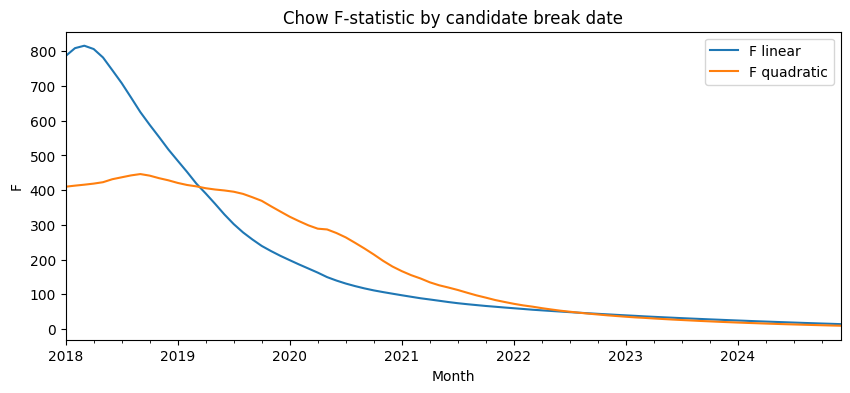

CUSUM (linear trend): stat = 2.506 | p-value = 0.0


In [ ]:
# Data-driven scan over candidate break dates (15% trimming), for both trend specifications
nn = len(ts); trim = int(0.15 * nn)
cands = list(range(trim, nn - trim))
scan = pd.DataFrame({
    "Month": ts["Month"].iloc[cands].values,
    "F linear": [chow_test(yt, Xt, b)[0] for b in cands],
    "F quadratic": [chow_test(yt, Xq, b)[0] for b in cands],
})
for col in ["F linear", "F quadratic"]:
    r = scan.loc[scan[col].idxmax()]
    print(f"{col:12s} max F = {r[col]:8.1f} at {r['Month'].strftime('%b-%Y')}")

scan.set_index("Month").plot(figsize=(10, 4), title="Chow F-statistic by candidate break date")
plt.ylabel("F"); plt.show()

stat, pval, _ = breaks_cusumolsresid(ols_t.resid, ddof=2)
print("CUSUM (linear trend): stat =", round(stat, 3), "| p-value =", round(pval, 4))

,Date,Mean growth pre (%),Mean growth post (%),Median pre,Median post,Welch p,Mann-Whitney p
0,Aug 2018 (methodology change),33.42,4.65,12.19,3.92,0.0050,0.0
1,Mar 2020 (COVID onset),22.32,3.74,10.54,3.41,0.0018,0.0


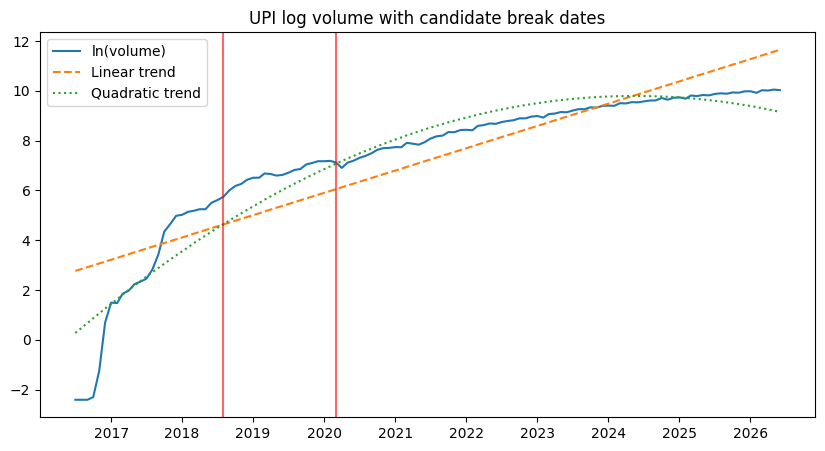

In [ ]:
rows = []
for label, d in dates.items():
    pre = ts.loc[ts["Month"] < d, "growth_pct"].dropna()
    post = ts.loc[ts["Month"] >= d, "growth_pct"].dropna()
    t_, p_ = stats.ttest_ind(pre, post, equal_var=False)
    u_, pu_ = stats.mannwhitneyu(pre, post)
    rows.append({"Date": label,
                 "Mean growth pre (%)": round(pre.mean(), 2), "Mean growth post (%)": round(post.mean(), 2),
                 "Median pre": round(pre.median(), 2), "Median post": round(post.median(), 2),
                 "Welch p": round(p_, 4), "Mann-Whitney p": round(pu_, 4)})
display(pd.DataFrame(rows))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ts["Month"], ts["ln_volume"], label="ln(volume)")
ax.plot(ts["Month"], ols_t.fittedvalues, "--", label="Linear trend")
ax.plot(ts["Month"], ols_q.fittedvalues, ":", label="Quadratic trend")
for label, d in dates.items():
    ax.axvline(pd.Timestamp(d), color="red", alpha=0.6)
ax.set_title("UPI log volume with candidate break dates"); ax.legend()
plt.show()

### Interpretation of Structural Break Analysis

The structural-break analysis examines whether the growth pattern of UPI transaction volume changed over time. The plots identify two candidate break dates: August 2018 and March 2020. The log-volume series shows a rapid increase during the earlier years, followed by a more gradual upward trend in later years. This suggests that UPI transaction growth has not followed a constant pattern throughout the study period.

August 2018 is a candidate break date that coincides with a change in NPCI's UPI transaction-reporting methodology. March 2020 coincides with the beginning of the COVID-19 period. These dates provide useful historical context for examining changes in the series, but the plots alone cannot establish that either event caused the changes in transaction growth.

The linear and quadratic trend comparisons help illustrate how different trend specifications fit the observed data. However, a better fit after introducing a break does not, by itself, establish a statistically significant structural change. The Chow test also relies on assumptions about the regression errors that may not hold for a trending time series. Therefore, the results should be interpreted as evidence of possible changes in the growth pattern rather than definitive proof of structural breaks.

Overall, the analysis supports examining UPI growth in different periods rather than assuming that a single trend describes the entire sample. These possible changes may also help explain why forecasting accuracy varies across periods, which can be investigated using the rolling-origin forecast errors.

## 13. Growth by sub-period and average ticket size

In [ ]:
edges = pd.to_datetime(["2016-04-30", "2018-07-31", "2020-02-29", "2021-03-31", "2026-12-31"])
labels = ["Jul16-Jul18", "Aug18-Feb20", "Mar20-Mar21", "Apr21-Jun26"]
ts["period"] = pd.cut(ts["Month"], bins=edges, labels=labels)

def cmgr(s):        # compound monthly growth rate over the period
    return (s.iloc[-1] / s.iloc[0]) ** (1 / (len(s) - 1)) - 1

g = ts.groupby("period", observed=True)
growth_tbl = g.agg(Months=("volume_mn", "size"), Start_vol=("volume_mn", "first"),
                   End_vol=("volume_mn", "last"), Mean_MoM=("growth_pct", "mean"),
                   Median_MoM=("growth_pct", "median"), SD_MoM=("growth_pct", "std"))
growth_tbl["CMGR (%)"] = g["volume_mn"].apply(cmgr) * 100
growth_tbl["Annualised (%)"] = ((1 + growth_tbl["CMGR (%)"] / 100) ** 12 - 1) * 100
display(growth_tbl.round(2))
growth_tbl.round(2).to_csv(DATA_DIR + "growth_by_period.csv")

,Months,Start_vol,End_vol,Mean_MoM,Median_MoM,SD_MoM,CMGR (%),Annualised (%)
period,,,,,,,,
Jul16-Jul18,25,0.09,273.75,33.42,12.19,45.29,39.68,5415.13
Aug18-Feb20,19,312.02,1325.69,8.30,8.14,8.34,8.37,162.33
Mar20-Mar21,13,1246.84,2731.68,5.56,7.80,11.15,6.75,119.09
Apr21-Jun26,63,2641.06,22716.07,3.36,3.01,5.54,3.53,51.66


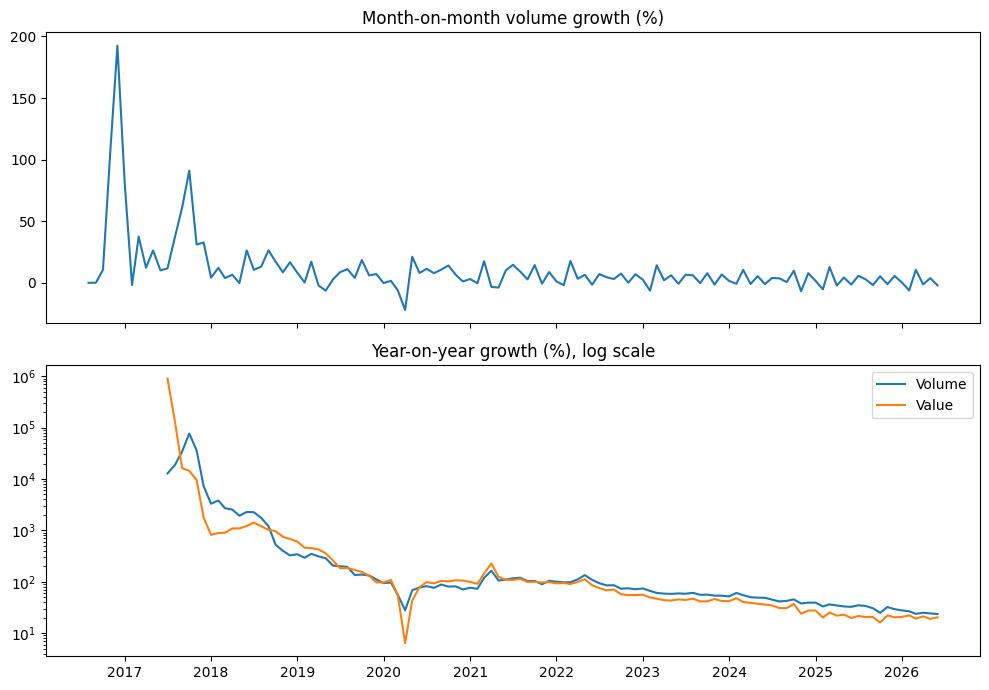

In [ ]:
ts["yoy_pct"] = ts["volume_mn"].pct_change(12) * 100
ts["yoy_value_pct"] = ts["value_cr"].pct_change(12) * 100

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(ts["Month"], ts["growth_pct"]); axes[0].set_title("Month-on-month volume growth (%)")
axes[1].plot(ts["Month"], ts["yoy_pct"], label="Volume")
axes[1].plot(ts["Month"], ts["yoy_value_pct"], label="Value")
axes[1].set_title("Year-on-year growth (%), log scale"); axes[1].legend(); axes[1].set_yscale("log")
plt.tight_layout(); plt.show()

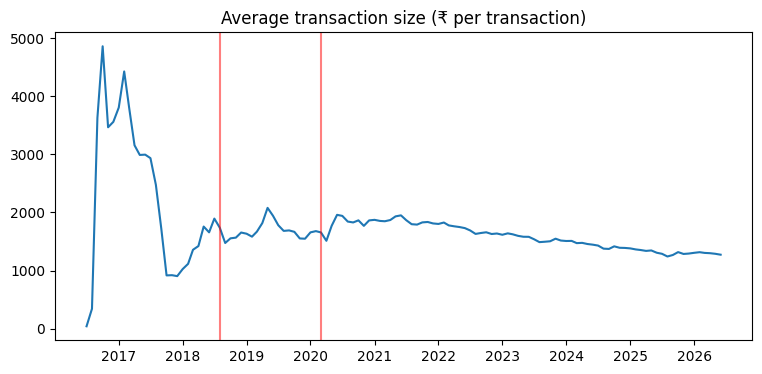

,first,last,mean,max
period,,,,
May16-Jul18,42.0,1894.0,2286.0,4857.0
Aug18-Feb20,1737.0,1678.0,1682.0,2078.0
Mar20-Mar21,1656.0,1848.0,1814.0,1958.0
Apr21-Jun26,1869.0,1273.0,1536.0,1950.0


Latest month: Jun-2026 → ₹ 1273


In [ ]:
# value_cr is in crore (1e7 ₹) and volume_mn in millions (1e6): ₹ per transaction = value*1e7 / (volume*1e6)
ts["ticket_rs"] = ts["value_cr"] * 10 / ts["volume_mn"]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(ts["Month"], ts["ticket_rs"])
for d in dates.values():
    ax.axvline(pd.Timestamp(d), color="red", alpha=0.5)
ax.set_title("Average transaction size (₹ per transaction)")
plt.show()

display(ts.groupby("period", observed=True)["ticket_rs"].agg(["first", "last", "mean", "max"]).round(0))
print("Latest month:", ts["Month"].iloc[-1].strftime("%b-%Y"), "→ ₹", round(ts["ticket_rs"].iloc[-1]))

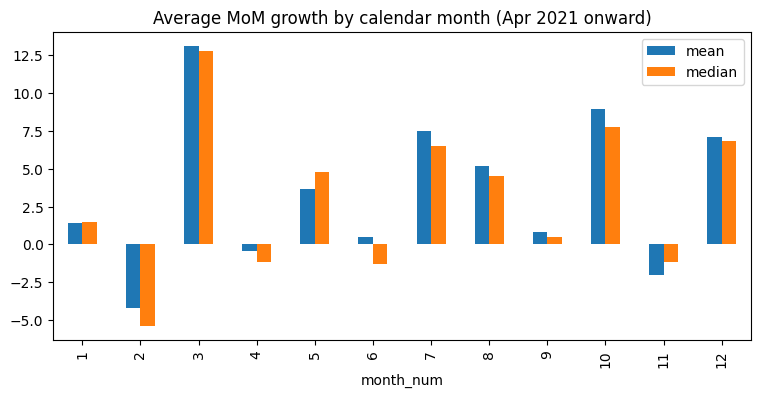

,mean,median
month_num,,
1,1.43,1.51
2,-4.17,-5.38
3,13.13,12.78
4,-0.45,-1.16
5,3.66,4.82
6,0.48,-1.30
7,7.53,6.53
8,5.19,4.53
9,0.82,0.52


In [ ]:
post = ts[ts["Month"] >= "2021-04-01"]
seas = post.groupby("month_num")["growth_pct"].agg(["mean", "median"]).round(2)
seas.plot.bar(figsize=(9, 4), title="Average MoM growth by calendar month (Apr 2021 onward)")
plt.show()
display(seas)

### Interpretation of Average Transaction Value and Monthly Growth

The average transaction value per UPI transaction changes considerably over the study period. The series shows unusually high and volatile values during the early months, followed by a decline and a more stable pattern from around 2018 onwards. The average transaction value subsequently fluctuates around a relatively stable range before gradually declining in the later years. The latest observation, for June 2026, is approximately ₹1,273 per transaction.

The period-wise summary indicates that average transaction value has not increased continuously alongside the expansion of UPI. This suggests that growth in total transaction value cannot automatically be interpreted as an increase in the size of individual transactions. Transaction volume and average transaction value must be examined together to understand the sources of growth.

The monthly growth chart for April 2021 onwards shows considerable differences across calendar months. Some months, particularly March, July, October and December, display higher average growth, while other months show lower or negative growth. However, the mean and median growth rates differ for several months, indicating that unusually large changes may influence the average. These patterns may reflect seasonal effects, irregular fluctuations or other factors; the chart alone cannot establish a specific cause.

Overall, the results suggest that UPI's expansion should be analysed through both transaction volume and average transaction value. The calendar-month differences also motivate further investigation into seasonality, although the observed patterns should not be treated as conclusive evidence of a recurring seasonal effect.

## 14. Diagnostics and robustness

Durbin-Watson: 1.688
Condition number: 40762.1
    lb_stat  lb_pvalue
6    9.8534     0.1310
12  35.1381     0.0004
Breusch-Pagan p-value: 0.0


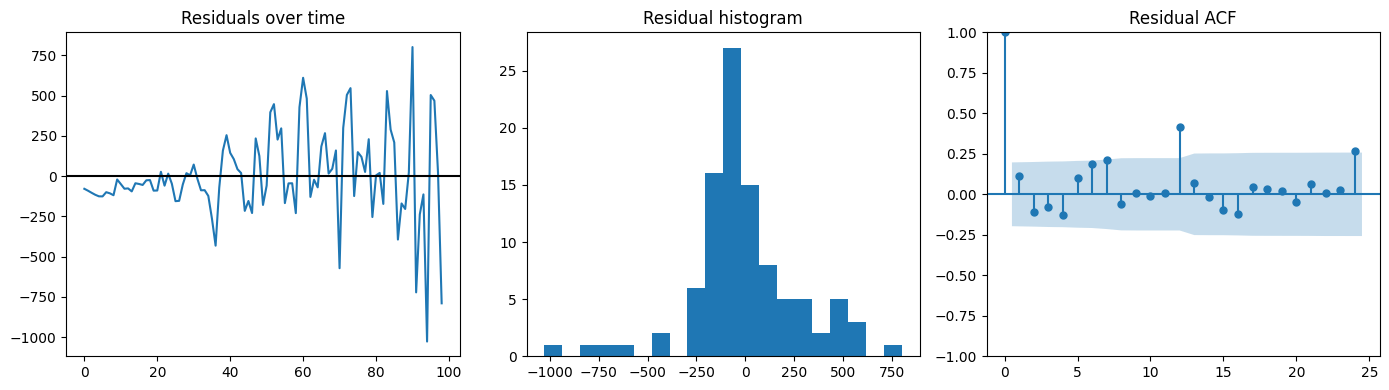

In [ ]:
# 14a. Residual diagnostics, linear regression (training fit)
res = ols.resid
print("Durbin-Watson:", round(durbin_watson(res), 3))
print("Condition number:", round(ols.condition_number, 1))
print(acorr_ljungbox(res, lags=[6, 12], return_df=True).round(4))
bp_stat, bp_p, _, _ = het_breuschpagan(res, ols.model.exog)
print("Breusch-Pagan p-value:", round(bp_p, 4))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(res.values); axes[0].axhline(0, color="k"); axes[0].set_title("Residuals over time")
axes[1].hist(res, bins=20); axes[1].set_title("Residual histogram")
plot_acf(res, lags=24, ax=axes[2]); axes[2].set_title("Residual ACF")
plt.tight_layout(); plt.show()

In [ ]:
# 14b. Forecast bias and error by target year (rolling forecasts)
bias = long.groupby("model").agg(Mean_error=("err", "mean"),
                                 Pct_over_forecast=("err", lambda s: (s > 0).mean() * 100)).round(1)
display(bias)

long["target_month"] = df_model["Month"].iloc[(long["origin"] + long["h"] - 1).values].values
long["target_year"] = pd.to_datetime(long["target_month"]).dt.year
display(long.pivot_table(index="model", columns="target_year", values="ape", aggfunc="mean").round(1))

,Mean_error,Pct_over_forecast
model,,
"ARIMA (last 36m, reselected)",1753.4,94.6
"ARIMA (last 48m, reselected)",2299.3,96.4
ARIMA (reselected),6771.8,96.4
Holt,-231.9,28.6
Holt damped,-316.4,26.2
Linear Reg. (recursive),1188.2,93.5
Naive,-2287.3,2.4
SES,-2312.4,2.4


target_year,2022,2023,2024,2025,2026
model,,,,,
"ARIMA (last 36m, reselected)",3.5,14.6,14.6,11.5,14.0
"ARIMA (last 48m, reselected)",11.3,18.6,17.0,16.8,15.6
ARIMA (reselected),33.1,53.2,46.6,45.2,72.2
Holt,3.2,5.0,3.5,2.3,2.8
Holt damped,3.5,5.5,3.7,2.5,2.9
Linear Reg. (recursive),6.1,12.0,8.3,7.6,11.0
Naive,15.5,20.9,17.2,13.7,16.3
SES,15.5,20.9,17.2,14.1,16.6


In [ ]:
# 14c. Robustness: different training start dates and test lengths
def run_split(start, test_len, label):
    o = len(y) - test_len
    y_tr, y_te = y.iloc[start:o], y.iloc[o:]
    X_tr, X_te = X.iloc[start:o], X.iloc[o:]
    rows = []
    for name, fn in models.items():
        p = np.asarray(fn(y_tr, X_tr, X_te))
        rows.append({**evaluate(name, y_te, p), "Setup": label})
    return pd.DataFrame(rows)

s_aug18 = int(df_model["Month"].searchsorted(pd.Timestamp("2018-08-01")))
s_jan19 = int(df_model["Month"].searchsorted(pd.Timestamp("2019-01-01")))

rob_start = pd.concat([run_split(0, 12, "Full history"),
                       run_split(s_aug18, 12, "From Aug 2018"),
                       run_split(s_jan19, 12, "From Jan 2019")], ignore_index=True)
rob_len = pd.concat([run_split(0, L, f"Test = {L} months") for L in (6, 12, 18)], ignore_index=True)

display(rob_start.pivot(index="Model", columns="Setup", values="RMSE").round(1))
display(rob_len.pivot(index="Model", columns="Setup", values="MAPE (%)").round(2))

Setup,From Aug 2018,From Jan 2019,Full history
Model,,,
"ARIMA (last 36m, reselected)",2162.6,2162.6,2162.6
"ARIMA (last 48m, reselected)",1510.6,1510.6,1510.6
ARIMA (reselected),3710.4,4463.6,8834.5
Holt,559.1,559.1,559.3
Holt damped,577.6,577.6,577.8
Linear Reg. (recursive),1879.5,1857.3,1892.8
Naive,3105.9,3105.9,3105.9
SES,3083.5,3083.5,3083.5


Setup,Test = 12 months,Test = 18 months,Test = 6 months
Model,,,
"ARIMA (last 36m, reselected)",7.89,17.80,6.88
"ARIMA (last 48m, reselected)",5.18,27.08,4.16
ARIMA (reselected),30.55,82.77,21.64
Holt,2.22,2.32,2.83
Holt damped,2.29,2.29,2.71
Linear Reg. (recursive),7.01,11.42,3.93
Naive,13.11,16.21,4.26
SES,13.00,16.64,4.71


In [ ]:
rank_tbl = pd.concat([rob_start.pivot(index="Model", columns="Setup", values="RMSE"),
                      rob_len.pivot(index="Model", columns="Setup", values="RMSE")], axis=1).rank()
display(rank_tbl)          # 1 = best; a stable rank across columns means a robust ranking
rob_start.to_csv(DATA_DIR + "robust_start_date.csv", index=False)
rob_len.to_csv(DATA_DIR + "robust_test_length.csv", index=False)

Setup,From Aug 2018,From Jan 2019,Full history,Test = 12 months,Test = 18 months,Test = 6 months
Model,,,,,,
"ARIMA (last 36m, reselected)",5.0,5.0,5.0,5.0,6.0,7.0
"ARIMA (last 48m, reselected)",3.0,3.0,3.0,3.0,7.0,6.0
ARIMA (reselected),8.0,8.0,8.0,8.0,8.0,8.0
Holt,1.0,1.0,1.0,1.0,2.0,2.0
Holt damped,2.0,2.0,2.0,2.0,1.0,1.0
Linear Reg. (recursive),4.0,4.0,4.0,4.0,3.0,3.0
Naive,7.0,7.0,7.0,7.0,4.0,4.0
SES,6.0,6.0,6.0,6.0,5.0,5.0


### Interpretation of Robustness Checks

The robustness analysis evaluates forecasting performance under different training start dates and test-window lengths. This helps determine whether the preferred forecasting model performs consistently or whether its ranking depends on the evaluation period.

When the training start date changes, Holt maintains a relatively low RMSE, ranging from approximately 558 to 569 across the three setups. Holt damped also performs consistently, with RMSE values around 577–578. In comparison, the ARIMA variants and recursive linear regression generally have higher errors. This suggests that Holt's performance is relatively stable under the alternative training-window specifications considered.

The test-window comparison also supports Holt's strong performance. Its reported MAPE is approximately 2.22% for a 12-month test window, 2.32% for an 18-month window and 2.83% for a 6-month window. Although the error changes across these windows, it remains comparatively low. Holt damped produces similar results, while the ARIMA and recursive linear regression models show larger errors in several configurations.

These results indicate that Holt is a strong candidate for forecasting UPI transaction volume within the tested evaluation settings. However, robustness across a limited number of alternative windows does not guarantee that the model will perform equally well during future structural changes. The results should therefore be considered alongside the rolling-origin evaluation and residual diagnostics.

Overall, the robustness checks strengthen the case for Holt as the preferred model because its forecasting performance remains comparatively strong when the training period and test-window length are varied.

In [ ]:

print("1. OVERALL ROLLING-ORIGIN MODEL PERFORMANCE")
display(rolling_summary.round(2))

print("2. FORECAST PERFORMANCE BY HORIZON")
display(
    horizon_summary.pivot(
        index="model",
        columns="horizon_band",
        values="MAE"
    ).round(2)
)

print("3. VOLUME, VALUE AND AVERAGE TRANSACTION VALUE GROWTH")
display(growth_comparison.round(2))


1. OVERALL ROLLING-ORIGIN MODEL PERFORMANCE


,model,MAE,RMSE,MAPE,Forecasts
0,Holt,452.93,566.96,3.54,168
1,Holt damped,494.30,612.93,3.85,168
2,Linear Reg. (recursive),1221.11,1507.36,9.08,168
3,"ARIMA (last 36m, reselected)",1768.52,2238.27,12.52,168
4,Naive,2304.76,2663.65,17.10,168
5,"ARIMA (last 48m, reselected)",2315.78,2926.79,16.73,168
6,SES,2325.33,2682.53,17.20,168
7,ARIMA (reselected),6791.75,8850.90,48.05,168


2. FORECAST PERFORMANCE BY HORIZON


horizon_band,Months 1-3,Months 4-6,Months 7-9,Months 10-12
model,,,,
"ARIMA (last 36m, reselected)",467.71,1139.78,2108.34,3358.26
"ARIMA (last 48m, reselected)",648.70,1505.39,2753.83,4355.21
ARIMA (reselected),1208.81,3864.56,8064.81,14028.84
Holt,303.80,396.19,488.11,623.62
Holt damped,308.67,409.68,542.73,716.12
Linear Reg. (recursive),346.47,773.84,1472.27,2291.86
Naive,736.73,1748.07,2821.64,3912.60
SES,743.91,1773.10,2846.67,3937.63


3. VOLUME, VALUE AND AVERAGE TRANSACTION VALUE GROWTH


,Period,Start month,End month,Volume growth (%),Total value growth (%),Average transaction value growth (%),Volume CAGR (%),Value CAGR (%),Average transaction value CAGR (%)
0,Full sample,Jul 2016,Jun 2026,25239977.78,7.610890e+08,2915.4,250.56,394.24,40.99
1,Recent five years,Jun 2021,Jun 2026,709.12,4.283700e+02,-34.7,51.92,39.51,-8.17
